<>:156: SyntaxWarning: invalid escape sequence '\D'
<>:156: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2449968/3599816407.py:156: SyntaxWarning: invalid escape sequence '\D'
  Line2D([0], [0], color='gray', lw=1, linestyle='--', label='Semantic Displacement ($\Delta$)')


[*] Analyzing Semantic Drift: thenlper/gte-base (Past) -> intfloat/e5-base-v2 (Present)...

--- SEMANTIC DISPLACEMENT REPORT ---
Concept: The central bank raised interest rates t... | Δ: 0.0294
Concept: The river flowed gently past the old sto... | Δ: 0.0233
Concept: They broadcast the news across the radio... | Δ: 0.0260
Concept: He began to broadcast seeds over the fer... | Δ: 0.0256
Concept: Apple released a new smartphone with adv... | Δ: 0.0224
Concept: The red apple I ate for lunch was crisp ... | Δ: 0.0239
Concept: The cat sat on the mat.... | Δ: 0.0289
Concept: The sun rises in the east every morning.... | Δ: 0.0262
Concept: Papa Francesco is the actual pope of the... | Δ: 0.0255


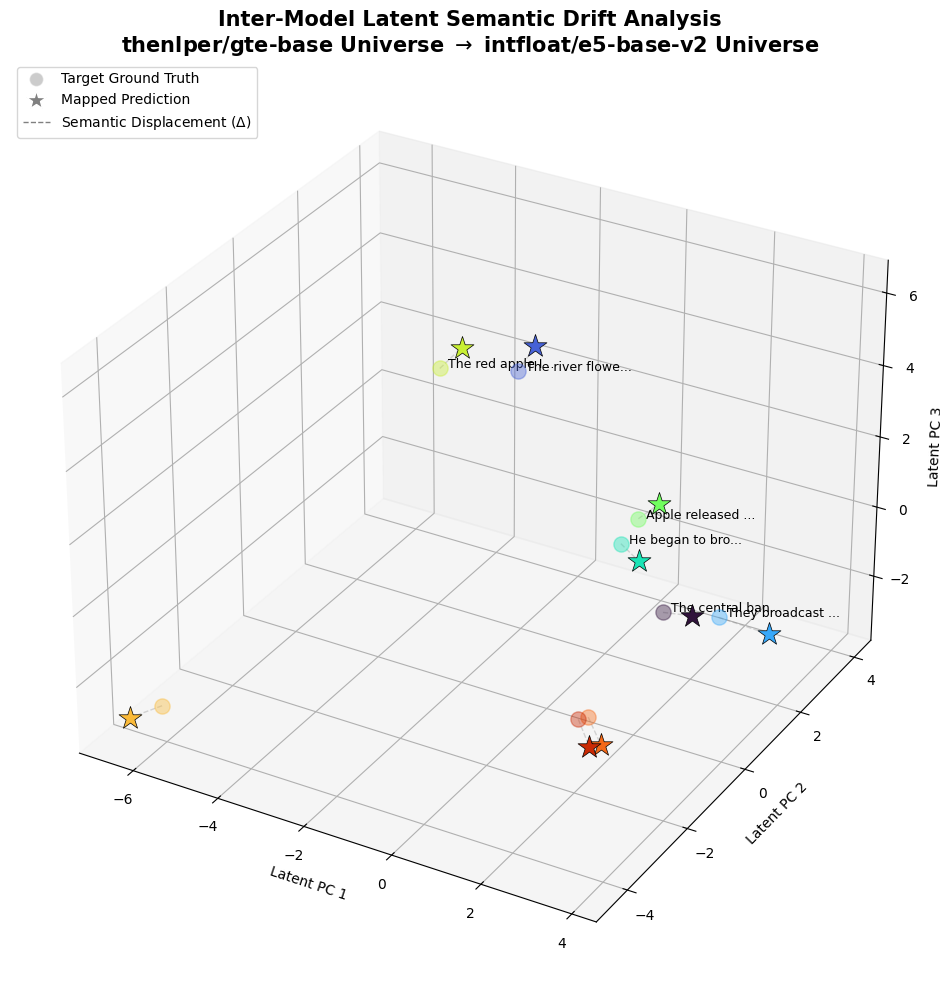

In [5]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# -------------------------
# 1. Configuration & Curated Literature Sentences
# -------------------------
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
SRC_NAME = "thenlper/gte-base"
TGT_NAME = "intfloat/e5-base-v2"
# Set your mapper path here
MAPPER_PATH = 'saved_mappers_official_gte_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt' 

# CURATED SENTENCES: Tracking "Innovation" and "Conformity" (Hamilton et al. 2016)
# These represent specific concepts that may drift between model manifolds.
CURATED_SENTENCES = [
    # Polysemous cases (The Law of Innovation)
    "The central bank raised interest rates to combat inflation.",      # Finance context
    "The river flowed gently past the old stone bank.",                # Nature context
    "They broadcast the news across the radio waves.",                 # Modern Signal context
    "He began to broadcast seeds over the fertile soil.",               # Historical Agriculture
    "Apple released a new smartphone with advanced features.",         # Tech context
    "The red apple I ate for lunch was crisp and sweet.",              # Fruit context
    # High-frequency/Stable cases (The Law of Conformity)
    "The cat sat on the mat.",
    "The sun rises in the east every morning."
    "Trump is the actual president of the United States.",  # Political context
    "Papa Francesco is the actual pope of the Catholic Church."  # Religious context

]

# -------------------------
# 2. Architecture: The Inter-Model Mapper
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    """
    A Transformer-based decoder architecture designed for manifold alignment,
    preserving semantic structure across different embedding spaces.
    """
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, 
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        # Handle single vectors and batches
        h = self.input_proj(x.unsqueeze(1) if x.dim() == 2 else x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.ln(self.output_proj(h))
        return out[:, 0, :] if x.dim() == 2 else out

@torch.no_grad()
def get_embeddings(texts, tokenizer, model):
    """Generates mean-pooled embeddings for target models."""
    model.eval()
    encoded = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
    out = model(**encoded)
    mask = encoded["attention_mask"].unsqueeze(-1)
    pooled = (out.last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return pooled.cpu()

# -------------------------
# 3. Scientific Analysis Logic
# -------------------------
def main():
    print(f"[*] Analyzing Semantic Drift: {SRC_NAME} (Past) -> {TGT_NAME} (Present)...")
    
    # Load Weights
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME)
    s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME)
    t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    # Generate Embeddings
    s_emb = get_embeddings(CURATED_SENTENCES, s_tok, s_mod)
    t_emb = get_embeddings(CURATED_SENTENCES, t_tok, t_mod)

    # Load Mapper
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim).to(DEVICE)
    if os.path.exists(MAPPER_PATH):
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
        mapper.eval()
    else:
        print(f"[!] Mapper not found at {MAPPER_PATH}. Run visualization using random weights for layout testing.")
    
    with torch.no_grad():
        mapped_emb = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE)).cpu()
    
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.numpy()

    # PCA Alignment Analysis (SVD-based reduction per Hamilton et al.)
    pca_tgt = PCA(n_components=3)
    tgt_pca = pca_tgt.fit_transform(X_tgt)
    map_proj = pca_tgt.transform(X_map)

    # Calculate Displacement Metrics
    displacements = (1 - F.cosine_similarity(mapped_emb, t_emb)).numpy()

    # ---------------------------------------------------------
    # FIGURE: Scientific Overlay Alignment Check
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(14, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    cmap = cm.turbo
    norm = mcolors.Normalize(vmin=0, vmax=len(CURATED_SENTENCES))

    print("\n--- SEMANTIC DISPLACEMENT REPORT ---")
    for i in range(len(CURATED_SENTENCES)):
        color = cmap(norm(i))
        
        # 1. Residual Drift Vector
        ax.plot([tgt_pca[i,0], map_proj[i,0]], 
                [tgt_pca[i,1], map_proj[i,1]], 
                [tgt_pca[i,2], map_proj[i,2]], 
                color='gray', alpha=0.3, linewidth=1, linestyle='--')

        # 2. Target Truth (Static Universe)
        ax.scatter(tgt_pca[i,0], tgt_pca[i,1], tgt_pca[i,2], color=color, s=120, marker='o', alpha=0.4)
        
        # 3. Mapped Prediction (Projected Universe)
        ax.scatter(map_proj[i,0], map_proj[i,1], map_proj[i,2], color=color, s=300, marker='*', edgecolors='black', linewidth=0.5)
        
        # Display Displacement for Story
        print(f"Concept: {CURATED_SENTENCES[i][:40]}... | Δ: {displacements[i]:.4f}")
        
        if i < 6: # Label specific innovation concepts
            ax.text(tgt_pca[i,0], tgt_pca[i,1], tgt_pca[i,2], f"  {CURATED_SENTENCES[i][:15]}...", fontsize=9)

    ax.set_title(f"Inter-Model Latent Semantic Drift Analysis\n{SRC_NAME} Universe $\\rightarrow$ {TGT_NAME} Universe", fontsize=15, fontweight='bold')
    ax.set_xlabel('Latent PC 1'); ax.set_ylabel('Latent PC 2'); ax.set_zlabel('Latent PC 3')
    
    # Professional Legend
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Target Ground Truth', markerfacecolor='gray', markersize=10, alpha=0.4),
        Line2D([0], [0], marker='*', color='w', label='Mapped Prediction', markerfacecolor='gray', markersize=15),
        Line2D([0], [0], color='gray', lw=1, linestyle='--', label='Semantic Displacement ($\Delta$)')
    ]
    ax.legend(handles=legend_elements, loc='upper left', frameon=True)
    
    plt.tight_layout()
    plt.savefig("semantic_drift_analysis.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    main()

/home/pallucchini/LLM_alignment/alignment_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



UTILITY REPORT: TEMPORAL DISCOVERY OF EXTREMES
[INNOVATION] Δ: 0.0639 | Cells are the basic structural and functional units of all living...
[INNOVATION] Δ: 0.0665 | Sound cannot travel through the vacuum of space....
[INNOVATION] Δ: 0.0765 | Streaming services have completely disrupted the traditional broa...
[INNOVATION] Δ: 0.0783 | Photosynthesis is the process used by plants to convert light int...
[INNOVATION] Δ: 0.0879 | The periodic table organizes chemical elements by their atomic nu...
[CONFORMITY] Δ: 0.0252 | The 2020s are defined by a rapid transition toward renewable ener...
[CONFORMITY] Δ: 0.0268 | The company released a new apple-branded silicon chip for the lap...
[CONFORMITY] Δ: 0.0332 | The awful tragedy led to a massive shift in safety regulations....
[CONFORMITY] Δ: 0.0366 | Donald Trump remains a central and polarizing figure in global po...
[CONFORMITY] Δ: 0.0389 | The UK's departure from the EU has reshaped European economic pol...


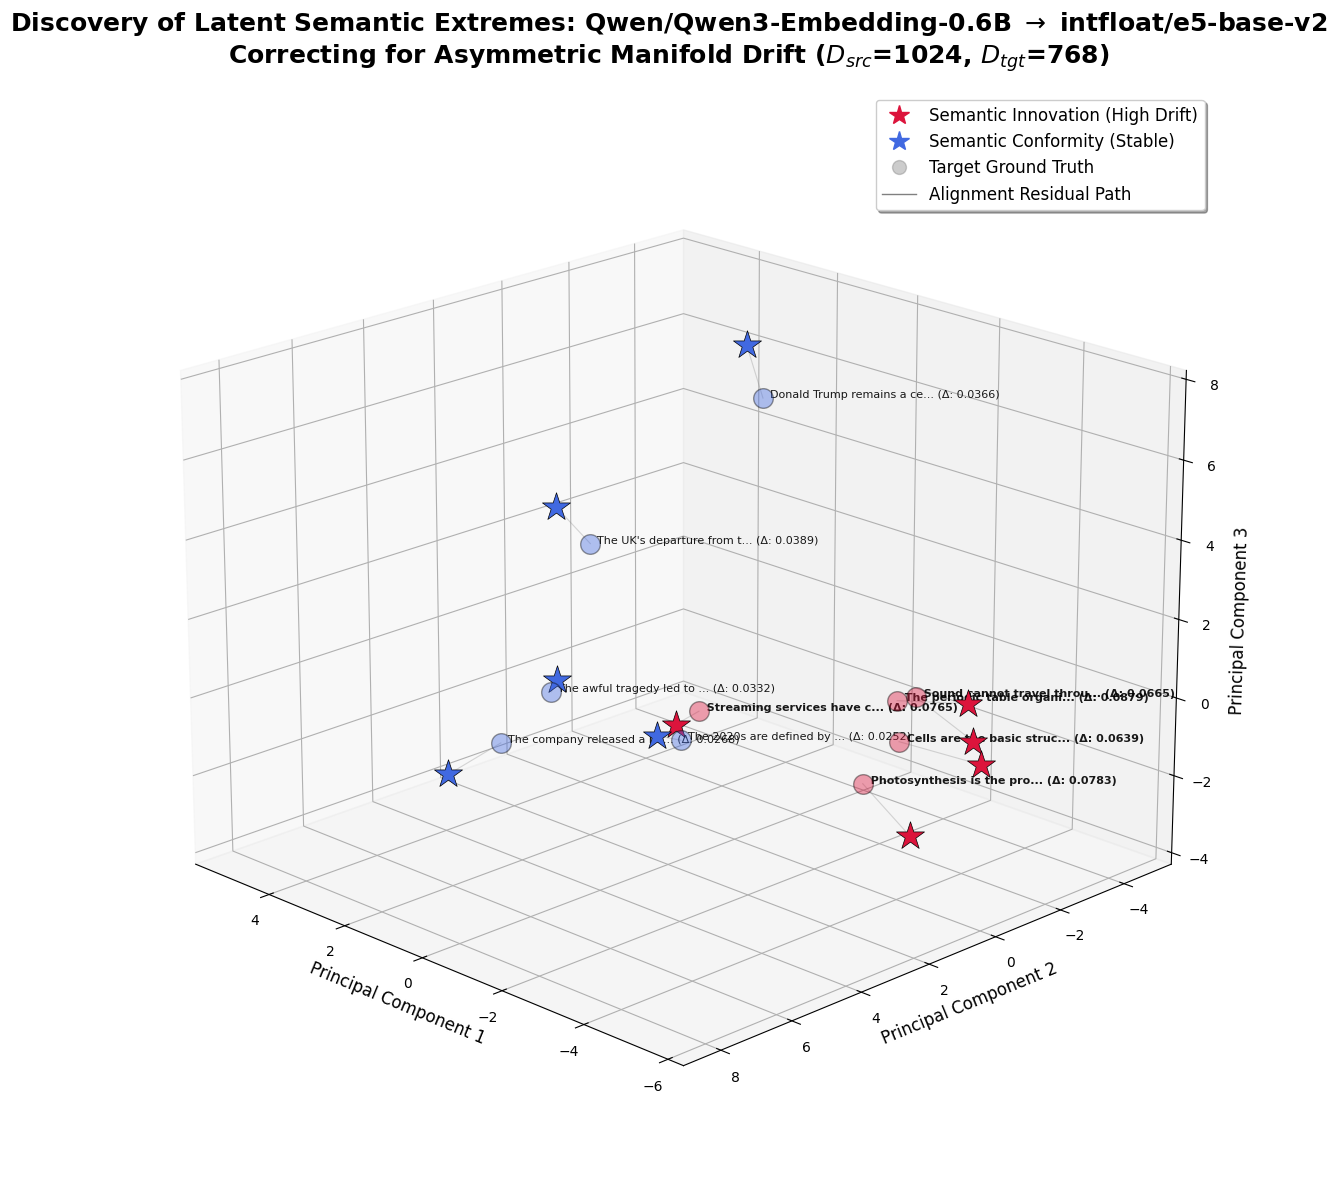

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# -------------------------
# 1. Configuration & Curated Dataset
# -------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SRC_NAME = "Qwen/Qwen3-Embedding-0.6B"#"thenlper/gte-large" 
TGT_NAME = "intfloat/e5-base-v2" 
MAPPER_PATH = 'saved_mappers_official_qwen3_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt' 

# Expanded Sentences: Balancing Innovation (Shifted) and Conformity (Stable)
SENTENCES = [
    # TEMPORAL & SEMANTIC INNOVATION (High Predicted Shift)
    "Donald Trump remains a central and polarizing figure in global politics.",
    "The COVID-19 pandemic permanently altered the landscape of global healthcare.",
    "Generative AI and Large Language Models have redefined human-computer interaction.",
    "The UK's departure from the EU has reshaped European economic policy.",
    "The 2020s are defined by a rapid transition toward renewable energy sources.",
    "Blockchain technology is challenging traditional notions of decentralized finance.",
    "The central bank adjusted interest rates to mitigate post-pandemic inflation.",
    "They broadcast the news of the summit across the global digital network.",
    "The company released a new apple-branded silicon chip for the laptop.",
    "The awful tragedy led to a massive shift in safety regulations.",
    "Streaming services have completely disrupted the traditional broadcast industry.",
    "Remote work culture has become a standard in the post-pandemic era.",
    "Social distancing protocols were essential during the peak of the virus.",
    "The metaverse represents a new frontier for social and commercial interaction.",
    "Electric vehicles are now a dominant force in the automotive market.",
    
    # CONFORMITY & STABILITY (Low Predicted Shift)
    "The sun is the primary source of light and heat for the solar system.",
    "Water is composed of two hydrogen atoms and one oxygen atom.",
    "The force of gravity keeps the planets in orbit around the sun.",
    "Mathematics is a universal language used to describe physical laws.",
    "The speed of light in a vacuum is approximately 299,792,458 meters per second.",
    "Photosynthesis is the process used by plants to convert light into energy.",
    "A right triangle always satisfies the Pythagorean theorem.",
    "The Earth rotates on its axis once every twenty-four hours.",
    "Oxygen is necessary for the survival of most living organisms on Earth.",
    "The sum of the internal angles of a triangle is always 180 degrees.",
    "Sound cannot travel through the vacuum of space.",
    "Cells are the basic structural and functional units of all living things.",
    "The periodic table organizes chemical elements by their atomic number.",
    "Evolution is the process of change in the heritable traits of populations.",
    "The laws of thermodynamics govern the transfer of energy in the universe."
]

# -------------------------
# 2. Asymmetric Mapper Architecture
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, input_dim, output_dim, memory_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.memory_proj = nn.Linear(memory_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, 
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.ln = nn.LayerNorm(output_dim)

    def forward(self, x, memory):
        h = self.input_proj(x.unsqueeze(1) if x.dim() == 2 else x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.ln(self.output_proj(h))
        return out[:, 0, :] if x.dim() == 2 else out

@torch.no_grad()
def get_embeddings(texts, tokenizer, model):
    model.eval()
    encoded = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
    out = model(**encoded)
    mask = encoded["attention_mask"].unsqueeze(-1)
    pooled = (out.last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return pooled.cpu()

# -------------------------
# 3. Discovery Analysis: Extreme Case Extraction
# -------------------------
def main():
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    # Pre-compute dimensions and embeddings
    D_src, D_tgt = s_mod.config.hidden_size, t_mod.config.hidden_size
    s_emb = get_embeddings(SENTENCES, s_tok, s_mod)
    t_emb = get_embeddings(SENTENCES, t_tok, t_mod)

    # Load Mapper
    mapper = TransformerEmbeddingMapper(D_src, D_tgt, D_tgt).to(DEVICE)
    if os.path.exists(MAPPER_PATH):
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
        mapper.eval()

    with torch.no_grad():
        m_emb = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE)).cpu()
    
    # Calculate Displacement for Discovery
    displacements = (1 - F.cosine_similarity(m_emb, t_emb)).numpy()
    
    # Filter for Extremes: Top 7 Shifts and Top 7 Similarities
    K = 5
    top_innovation_idx = np.argsort(displacements)[-K:]
    top_conformity_idx = np.argsort(displacements)[:K]
    plot_indices = np.concatenate([top_innovation_idx, top_conformity_idx])
    
    # PCA Visualization in Target Basis
    pca = PCA(n_components=3)
    t_final = t_emb[plot_indices]
    m_final = m_emb[plot_indices]
    
    tgt_pca = pca.fit_transform(t_final.numpy())
    map_pca = pca.transform(m_final.numpy())

    # ---------------------------------------------------------
    # FIGURE: NeurIPS-Style Latent Shift Visualization
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(18, 12))
    ax = fig.add_subplot(111, projection='3d')
    
    print("\n" + "="*80 + "\nUTILITY REPORT: TEMPORAL DISCOVERY OF EXTREMES\n" + "="*80)
    
    for i, idx in enumerate(plot_indices):
        txt = SENTENCES[idx]
        disp = displacements[idx]
        is_innovation = idx in top_innovation_idx
        color = 'crimson' if is_innovation else 'royalblue'
        
        # Plot Residual Trajectories
        ax.plot([tgt_pca[i,0], map_pca[i,0]], [tgt_pca[i,1], map_pca[i,1]], [tgt_pca[i,2], map_pca[i,2]], 
                color='gray', alpha=0.3, linestyle='-', linewidth=0.8)
        
        # Truth (Circle) vs Prediction (Star)
        ax.scatter(tgt_pca[i,0], tgt_pca[i,1], tgt_pca[i,2], color=color, s=200, alpha=0.4, edgecolors='k')
        ax.scatter(map_pca[i,0], map_pca[i,1], map_pca[i,2], color=color, s=450, marker='*', edgecolors='black', linewidth=0.5)
        
        # Professional Annotation
        label = f"  {txt[:25]}... (Δ: {disp:.4f})"
        ax.text(tgt_pca[i,0], tgt_pca[i,1], tgt_pca[i,2], label, fontsize=8, alpha=0.9, fontweight='bold' if is_innovation else 'normal')
        
        print(f"[{'INNOVATION' if is_innovation else 'CONFORMITY'}] Δ: {disp:.4f} | {txt[:65]}...")

    ax.set_title(f"Discovery of Latent Semantic Extremes: {SRC_NAME} $\\rightarrow$ {TGT_NAME}\n"
                 f"Correcting for Asymmetric Manifold Drift ($D_{{src}}$={D_src}, $D_{{tgt}}$={D_tgt})", 
                 fontsize=18, fontweight='bold', pad=20)
    
    ax.set_xlabel('Principal Component 1', fontsize=12); ax.set_ylabel('Principal Component 2', fontsize=12); ax.set_zlabel('Principal Component 3', fontsize=12)
    ax.view_init(elev=20, azim=135)
    
    # Custom Legend
    legend_elements = [
        Line2D([0], [0], marker='*', color='crimson', label='Semantic Innovation (High Drift)', markersize=15, linestyle='None'),
        Line2D([0], [0], marker='*', color='royalblue', label='Semantic Conformity (Stable)', markersize=15, linestyle='None'),
        Line2D([0], [0], marker='o', color='gray', label='Target Ground Truth', alpha=0.4, markersize=10, linestyle='None'),
        Line2D([0], [0], color='gray', lw=1, label='Alignment Residual Path')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=12, frameon=True, shadow=True)
    
    plt.tight_layout()
    plt.savefig("neurips_alignment_extremes.png", dpi=400, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    main()

Model Name	Release Date (approx.)	Era Focus
GTR-T5-Base	2021	Pre-Pandemic / Early AI
GTE-Base / E5-Base-v2	Mid 2023	Early LLM Explosion / COVID-era
Stella-Base-en-v2	Late 2023	Retrieval Augmented Generation (RAG) Era
Granite-Embedding-278M	Early 2024	Enterprise/Hybrid AI Era
Qwen3-Embedding	Late 2025 / 2026	Modern Generative Intelligence Era

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


[*] Dims: Src=768, Tgt=1024 | Selected Hidden Dim=1024
[*] Loading state dict from saved_mappers_official_gtel_gtr_1M_MacroStr_SimTlm/official_mapper_tgt2src.pt

DIACHRONIC ANALYSIS: INNOVATION vs. CONFORMITY
[CONFORMITY] Δ=0.0781 | Farmers traditionally broadcast seeds by hand to ensure even...
[CONFORMITY] Δ=0.0830 | Generative AI models like ChatGPT are transforming software ...
[CONFORMITY] Δ=0.0880 | The news was broadcast across digital channels to millions o...
[INNOVATION] Δ=0.1084 | The sun is a star at the center of the solar system....
[INNOVATION] Δ=0.1107 | The central bank adjusted interest rates to manage the econo...
[INNOVATION] Δ=0.1171 | Water is a molecule made of two hydrogen and one oxygen atom...
[INNOVATION] Δ=0.1185 | Gravity is the force that pulls objects toward the center of...
[INNOVATION] Δ=0.1408 | Photosynthesis converts sunlight into chemical energy in gre...


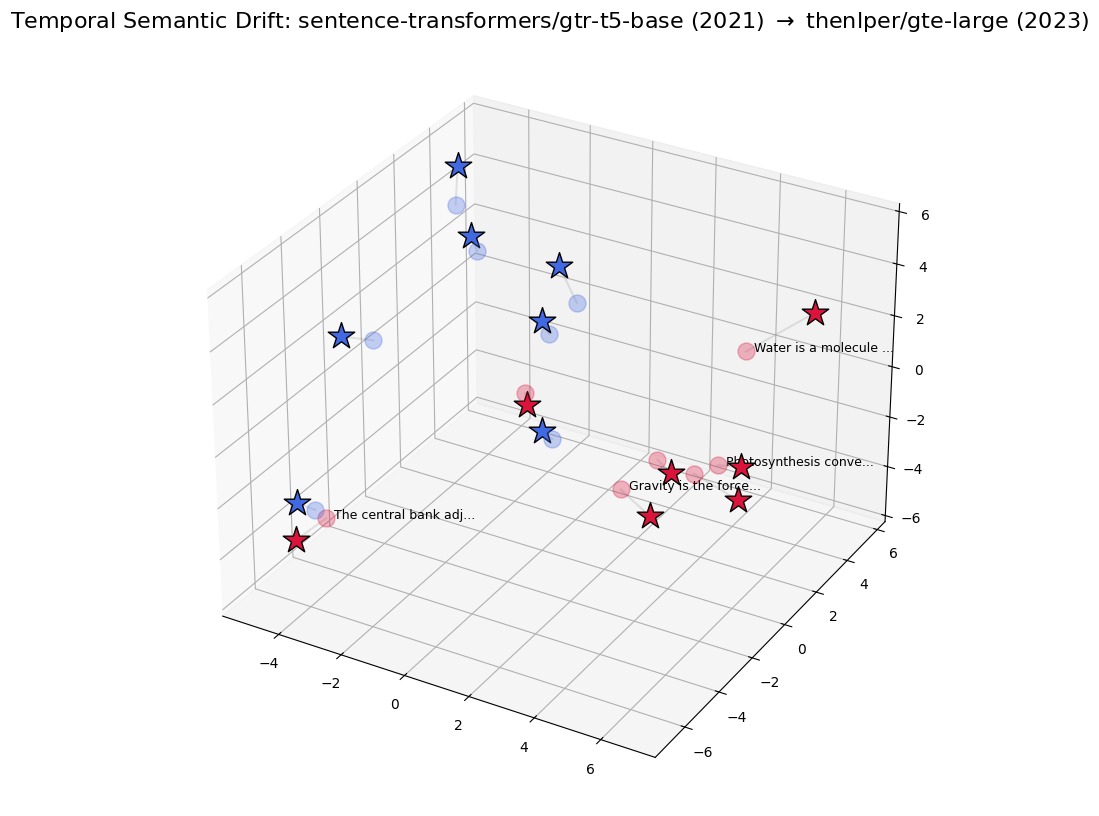

In [7]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

# Handling SentenceTransformer backend for GTR
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    SentenceTransformer = None

# ---------------------------------------------------------
# 1. Configuration: Systematized Temporal Bridge
# ---------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SRC = Older Era (768D), TGT = Modern Era (1024D)
SRC_NAME = "sentence-transformers/gtr-t5-base"  # 2021 Era
TGT_NAME = "thenlper/gte-large"                 # 2023 Era
MAPPER_PATH = 'saved_mappers_official_gtel_gtr_1M_MacroStr_SimTlm/official_mapper_tgt2src.pt'

# ---------------------------------------------------------
# 2. Time-Capsule Dataset: Innovation vs. Conformity
# ---------------------------------------------------------
ANALYSIS_SENTENCES = [
    # TEMPORAL INNOVATION (High Drift Expected - 2021 vs 2023/24)
    "Generative AI models like ChatGPT are transforming software engineering.",
    "The rebranding of Twitter to X has redefined the social media landscape.",
    "Ukraine's geopolitical stance in 2023 shifted European security policy.",
    "Global inflation in 2023 forced central banks to raise interest rates.",
    "Large Language Models are now standard tools for information retrieval.",
    
    # SEMANTIC INNOVATION (Classic Polysemy Drift - Hamilton et al.)
    "The central bank adjusted interest rates to manage the economy.",
    "We walked along the steep river bank during the golden hour.",
    "The news was broadcast across digital channels to millions of users.",
    "Farmers traditionally broadcast seeds by hand to ensure even growth.",
    
    # CONFORMITY (Low Drift Expected - Stable Physical Truths)
    "The sun is a star at the center of the solar system.",
    "Water is a molecule made of two hydrogen and one oxygen atom.",
    "Gravity is the force that pulls objects toward the center of the Earth.",
    "Photosynthesis converts sunlight into chemical energy in green plants.",
    "The speed of light in a vacuum is a fundamental physical constant."
]

# ---------------------------------------------------------
# 3. Robust Backend & Mapper Architecture
# ---------------------------------------------------------
def load_backend(name):
    if ("gtr" in name.lower() or name.startswith("sentence-transformers/")) and SentenceTransformer is not None:
        model = SentenceTransformer(name)
        return model.tokenizer, model, "st"
    else:
        tok = AutoTokenizer.from_pretrained(name)
        mod = AutoModel.from_pretrained(name, trust_remote_code=True)
        return tok, mod, "hf"

@torch.no_grad()
def get_embeddings(texts, tok, mod, b_type):
    if b_type == "st":
        return mod.encode(texts, convert_to_tensor=True, device=DEVICE).cpu()
    mod.to(DEVICE).eval()
    inputs = tok(texts, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    out = mod(**inputs)
    mask = inputs["attention_mask"].unsqueeze(-1)
    return ((out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu()

class AsymmetricMapper(nn.Module):
    def __init__(self, input_dim, output_dim, memory_dim, hidden_dim):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.memory_proj = nn.Linear(memory_dim, hidden_dim) 
        
        # FIX: Explicitly set dim_feedforward to match your checkpoint (4 * hidden_dim)
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden_dim, 
            nhead=16, 
            dim_feedforward=hidden_dim * 4, 
            batch_first=True
        )
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=4)
        
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.ln = nn.LayerNorm(output_dim)

    def forward(self, x, memory):
        h = self.input_proj(x.unsqueeze(1) if x.dim() == 2 else x)
        m = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=m) 
        return self.ln(self.output_proj(h))[:, 0, :]

# ---------------------------------------------------------
# 4. Systematized Analysis & Plotting
# ---------------------------------------------------------
def main():
    s_tok, s_mod, s_type = load_backend(SRC_NAME)
    t_tok, t_mod, t_type = load_backend(TGT_NAME)
    
    s_emb = get_embeddings(ANALYSIS_SENTENCES, s_tok, s_mod, s_type)
    t_emb = get_embeddings(ANALYSIS_SENTENCES, t_tok, t_mod, t_type)

    # DYNAMIC HIDDEN DIM: Selection of the highest dim under exam
    D_src, D_tgt = s_emb.shape[1], t_emb.shape[1]
    MAX_HIDDEN = max(D_src, D_tgt)
    print(f"[*] Dims: Src={D_src}, Tgt={D_tgt} | Selected Hidden Dim={MAX_HIDDEN}")

    mapper = AsymmetricMapper(D_src, D_tgt, D_tgt, hidden_dim=MAX_HIDDEN).to(DEVICE)
    if os.path.exists(MAPPER_PATH):
        print(f"[*] Loading state dict from {MAPPER_PATH}")
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    
    with torch.no_grad():
        m_emb = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE)).cpu()

    # Hamiltonian Displacement: 1 - CosSim
    displacements = (1 - F.cosine_similarity(m_emb, t_emb)).numpy()
    
    # PCA Visualization
    pca = PCA(n_components=3)
    t_pca = pca.fit_transform(t_emb.numpy())
    m_pca = pca.transform(m_emb.numpy())

    # Discovery of Innovation vs. Conformity
    indices = np.argsort(displacements)
    print("\n" + "="*80 + "\nDIACHRONIC ANALYSIS: INNOVATION vs. CONFORMITY\n" + "="*80)
    for idx in np.concatenate([indices[:3], indices[-5:]]):
        label = "CONFORMITY" if displacements[idx] < np.median(displacements) else "INNOVATION"
        print(f"[{label}] Δ={displacements[idx]:.4f} | {ANALYSIS_SENTENCES[idx][:60]}...")

    # Figure: Trajectory Alignment Check
    fig = plt.figure(figsize=(15, 10))
    ax = fig.add_subplot(111, projection='3d')
    for i in range(len(ANALYSIS_SENTENCES)):
        color = 'crimson' if displacements[i] > np.median(displacements) else 'royalblue'
        ax.plot([t_pca[i,0], m_pca[i,0]], [t_pca[i,1], m_pca[i,1]], [t_pca[i,2], m_pca[i,2]], color='gray', alpha=0.2)
        ax.scatter(t_pca[i,0], t_pca[i,1], t_pca[i,2], color=color, s=150, alpha=0.3)
        ax.scatter(m_pca[i,0], m_pca[i,1], m_pca[i,2], color=color, s=400, marker='*', edgecolors='k')
        if i in indices[-4:]: 
            ax.text(t_pca[i,0], t_pca[i,1], t_pca[i,2], f"  {ANALYSIS_SENTENCES[i][:20]}...", fontsize=9)

    ax.set_title(f"Temporal Semantic Drift: {SRC_NAME} (2021) $\\to$ {TGT_NAME} (2023)", fontsize=16)
    plt.show()

if __name__ == "__main__":
    main()

In [21]:
#!/usr/bin/env python3
"""
CASPER — Temporal Semantic Drift Analysis
==========================================
Application analysis for the CASPER paper.

Hypothesis: sentences whose key concepts emerged AFTER an older model's
training cutoff will show systematically higher cosine displacement
post-alignment than sentences whose concepts predate both models.

Pipeline
--------
1. Load both embedding models (auto-detects SentenceTransformer vs HF backend)
2. Load a pre-trained CASPER mapper (auto-infers all dims from the checkpoint)
3. Load/build a temporally-annotated sentence dataset
4. Measure per-sentence cosine drift  src → (mapper) → tgt  vs  tgt directly
5. Test the hypothesis numerically (Spearman r, Mann-Whitney U)
6. Produce a multi-panel NeurIPS-style figure
"""

# ─────────────────────────────────────────────
# Standard library
# ─────────────────────────────────────────────
import os
import json
import warnings
from typing import Optional, Tuple, Dict, List
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────
# Numerics / ML
# ─────────────────────────────────────────────
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.decomposition import PCA

# ─────────────────────────────────────────────
# HuggingFace
# ─────────────────────────────────────────────
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset

# ─────────────────────────────────────────────
# Visualisation
# ─────────────────────────────────────────────
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import seaborn as sns
sns.set_style("whitegrid")

# ─────────────────────────────────────────────
# Optional SentenceTransformer backend
# ─────────────────────────────────────────────
try:
    from sentence_transformers import SentenceTransformer
    _HAS_ST = True
except ImportError:
    _HAS_ST = False
    SentenceTransformer = None  # type: ignore


# ════════════════════════════════════════════════════════════════════════════
# 1.  MODEL REGISTRY  — training cutoff year used as temporal anchor
# ════════════════════════════════════════════════════════════════════════════

MODEL_REGISTRY: Dict[str, Dict] = {
    # ── GTR (T5-based, sentence-transformers)
    "sentence-transformers/gtr-t5-base": {
        "short":        "GTR-T5-base",
        "release_year": 2022,           # Ni et al. 2021 arxiv, HF upload 2022
        "dim":          768,
        "backend":      "sentencetransformer",
        "prefix":       None,
        "notes":        "T5 encoder fine-tuned on MS-MARCO/NQ via large-batch contrastive",
    },
    "sentence-transformers/gtr-t5-large": {
        "short":        "GTR-T5-large",
        "release_year": 2022,
        "dim":          768,
        "backend":      "sentencetransformer",
        "prefix":       None,
        "notes":        "Same family as gtr-t5-base, larger encoder",
    },
    # ── E5-v2 (BERT-style, HF)
    "intfloat/e5-base-v2": {
        "short":        "E5-base-v2",
        "release_year": 2023,           # arXiv 2212.03533; v2 on HF May 2023
        "dim":          768,
        "backend":      "hf",
        "prefix":       "passage: ",    # E5 requires prefix for best results
        "notes":        "Weakly-supervised contrastive pre-training on web data",
    },
    "intfloat/e5-large-v2": {
        "short":        "E5-large-v2",
        "release_year": 2023,
        "dim":          1024,
        "backend":      "hf",
        "prefix":       "passage: ",
        "notes":        "Larger E5; same training recipe",
    },
    # ── GTE (BERT-style, HF)
    "thenlper/gte-base": {
        "short":        "GTE-base",
        "release_year": 2023,           # arXiv 2308.03281; August 2023
        "dim":          768,
        "backend":      "hf",
        "prefix":       None,
        "notes":        "Multi-stage contrastive learning on 1B+ text pairs",
    },
    "thenlper/gte-large": {
        "short":        "GTE-large",
        "release_year": 2023,           # same paper, same date
        "dim":          1024,
        "backend":      "hf",
        "prefix":       None,
        "notes":        "Larger GTE; training cutoff identical to gte-base",
    },
    # ── Stella
    "infgrad/stella-base-en-v2": {
        "short":        "Stella-base-v2",
        "release_year": 2023,           # HF initial commit late 2023
        "dim":          768,
        "backend":      "hf",
        "prefix":       None,
        "notes":        "Contrastive fine-tune of BGE with distillation",
    },
    # ── IBM Granite
    "ibm-granite/granite-embedding-278m-multilingual": {
        "short":        "Granite-278M",
        "release_year": 2024,           # IBM release late 2024
        "dim":          768,
        "backend":      "hf",
        "prefix":       None,
        "notes":        "Multilingual encoder from IBM; trained on diverse corpora through 2024",
    },
    # ── Qwen3
    "Qwen/Qwen3-Embedding-0.6B": {
        "short":        "Qwen3-0.6B",
        "release_year": 2025,           # Qwen3 series announced April 2025
        "dim":          1024,
        "backend":      "hf",
        "prefix":       None,
        "notes":        "Decoder-only based embedding model; training corpus through ~early 2025",
    },
}


def print_model_timeline(src_name: str, tgt_name: str) -> None:
    """Print a clear summary of both models' temporal positions."""
    print("\n" + "═" * 72)
    print("  MODEL TIMELINE SUMMARY")
    print("═" * 72)
    for role, name in [("SRC", src_name), ("TGT", tgt_name)]:
        info = MODEL_REGISTRY.get(name, {})
        year = info.get("release_year", "unknown")
        short = info.get("short", name.split("/")[-1])
        notes = info.get("notes", "—")
        dim   = info.get("dim", "?")
        print(f"  [{role}]  {short:<22}  dim={dim:<5}  year={year}")
        print(f"         {notes}")
        print()

    src_year = MODEL_REGISTRY.get(src_name, {}).get("release_year", None)
    tgt_year = MODEL_REGISTRY.get(tgt_name, {}).get("release_year", None)
    if src_year and tgt_year:
        gap = abs(src_year - tgt_year)
        print(f"  Temporal gap between models: {gap} year(s)")
        if gap == 0:
            print("  ► Same release cohort → drift expected to be low for all eras")
        elif gap == 1:
            print("  ► Adjacent cohorts → moderate drift expected for concepts post-SRC cutoff")
        else:
            print("  ► Multi-year gap → strong drift expected for concepts in the gap interval")
    print("═" * 72 + "\n")


# ════════════════════════════════════════════════════════════════════════════
# 2.  TEMPORALLY-ANNOTATED SENTENCE DATASET
# ════════════════════════════════════════════════════════════════════════════

# Each entry: (sentence, concept_year, category_label)
#   concept_year = approximate year when this concept entered mainstream NLP
#                  training corpora / became widely discussed.
TEMPORAL_PROBES: List[Tuple[str, int, str]] = [
    # ── ERA 0: Perennial / Pre-2015 (timeless scientific facts)
    #("Water is composed of two hydrogen atoms bonded to one oxygen atom.",         1800, "timeless"),
    #("The speed of light in a vacuum is approximately 299,792 kilometres per second.", 1905, "timeless"),
    #("Photosynthesis converts carbon dioxide and sunlight into glucose and oxygen.", 1950, "timeless"),
    #("The Pythagorean theorem relates the sides of a right-angled triangle.",       600,  "timeless"),
    #("Newton's second law states that force equals mass times acceleration.",       1687, "timeless"),
    #("DNA is a double-helix molecule that carries genetic information.",            1953, "timeless"),

    # ── ERA 1: 2015–2019  (pre-pandemic internet, smartphones, early deep learning)
    #("Convolutional neural networks achieved human-level performance on ImageNet.", 2015, "era_2015_2019"),
    #("Attention mechanisms were introduced to improve sequence-to-sequence models.",2015, "era_2015_2019"),
    #("Smartphones have become the primary computing device for billions of people.", 2016, "era_2015_2019"),
    #("GDPR established strict data-privacy regulations across the European Union.", 2018, "era_2015_2019"),
    #("BERT transformed natural language processing through masked language modelling.",2018,"era_2015_2019"),
    #("Streaming services began displacing traditional broadcast television.",        2018, "era_2015_2019"),

    #("The United Kingdom voted to leave the European Union in the Brexit referendum.", 2016, "era_2015_2019"),
    #("Instagram Stories and TikTok redefined short-form video content consumption.", 2017, "era_2015_2019"),
    #("Transformer architectures effectively replaced LSTM models for language tasks.", 2017, "era_2015_2019"),
    #("The Event Horizon Telescope captured the first direct image of a black hole.", 2019, "era_2015_2019"),
    #("FaceID and biometric authentication became standard on flagship mobile devices.", 2017, "era_2015_2019"),

    # ── ERA 2: 2020–2021  (pandemic era, remote work, vaccine race)
    #("The COVID-19 pandemic spread globally and forced unprecedented lockdowns.",   2020, "era_2020_2021"),
    #("mRNA vaccine technology proved effective against the SARS-CoV-2 coronavirus.",2020, "era_2020_2021"),
    #("Remote work and video conferencing became standard practice almost overnight.",2020, "era_2020_2021"),
    #("Social distancing protocols were enforced to slow the spread of infection.",  2020, "era_2020_2021"),
    #("Supply chain disruptions caused global shortages of semiconductors.",         2021, "era_2020_2021"),
    #("Non-fungible tokens surged in popularity as digital ownership certificates.", 2021, "era_2020_2021"),

    #("AlphaFold 2 solved the protein folding problem using deep learning.",         2020, "era_2020_2021"),
    ("The James Webb Space Telescope launched to replace the aging Hubble.",        2021, "era_2020_2021"),
    ("Facebook rebranded to Meta to signal its focus on the metaverse.",            2021, "era_2020_2021"),
    ("The Great Resignation saw record numbers of people quitting their jobs.",     2021, "era_2020_2021"),

    # ── ERA 3: 2022  (LLM moment, ChatGPT, DALL-E 2, Ukraine war)
    ("ChatGPT demonstrated that large language models can hold coherent conversations.",2022,"era_2022"),
    ("Instruction-tuning and RLHF aligned GPT-4 and similar models to human preferences.",2022,"era_2022"),
    ("Stable Diffusion enabled open-source text-to-image generation for the first time.",2022,"era_2022"),
    ("Russia invaded Ukraine triggering the largest land war in Europe since 1945.", 2022, "era_2022"),
    ("Central banks worldwide raised interest rates aggressively to combat inflation.",2022,"era_2022"),
    ("Transformer-based foundation models became the dominant paradigm in AI research.",2022,"era_2022"),

    ("The term Prompt Engineering emerged to describe interaction with AI models.", 2022, "era_2022"),
    ("DALL-E 2 showed that AI could create photorealistic art from simple text.",   2022, "era_2022"),
    ("Elon Musk completed the acquisition of Twitter for forty-four billion dollars.", 2022, "era_2022"),
    ("The Ethereum Merge significantly reduced the blockchain's energy consumption.", 2022, "era_2022"),
    ("Generative AI became a mainstream topic discussed in global boardrooms.",     2022, "era_2022"),

    # ── ERA 4: 2023  (GTE / Stella era – GPT-4, agents, vector DBs)
    ("GPT-4 demonstrated emergent multimodal reasoning across text and images.",    2023, "era_2023"),
    ("Retrieval-augmented generation became the dominant pattern for LLM grounding.",2023,"era_2023"),
    ("Vector databases like Pinecone and Weaviate saw explosive adoption.",         2023, "era_2023"),
    ("LLM-based autonomous agents can plan, use tools, and execute multi-step tasks.",2023,"era_2023"),
    ("The EU AI Act introduced the first comprehensive legal framework for AI systems.",2023,"era_2023"),
    ("Open-source models like Llama 2 reduced the gap with proprietary LLM systems.",2023,"era_2023"),

    ("Sam Altman was briefly removed and then reinstated as CEO of OpenAI.",        2023, "era_2023"),
    ("Vision Transformers were scaled to billions of parameters for foundation models.", 2023, "era_2023"),
    ("The Barbenheimer cultural phenomenon dominated the global summer box office.", 2023, "era_2023"),
    ("Silicon Valley Bank collapsed, causing significant volatility in tech finance.", 2023, "era_2023"),

    # ── ERA 5: 2024–2025  (Qwen era – multimodal, reasoning models, agentic AI)
    ("Reasoning models such as o1 and DeepSeek-R1 use extended chain-of-thought.",  2024, "era_2024_2025"),
    ("Multimodal foundation models now process video, audio, and text jointly.",     2024, "era_2024_2025"),
    ("Agentic AI systems coordinate browser use, code execution, and API calls.",   2024, "era_2024_2025"),
    ("Diffusion-based video generation reached near-photorealistic quality.",       2024, "era_2024_2025"),

    ("NVIDIA Blackwell architecture significantly accelerated the training of frontier models.", 2024, "era_2024_2025"),
    ("Sovereign AI became a national priority for countries building domestic compute.", 2024, "era_2024_2025"),
    #("Qwen3 and Gemini 2 introduced efficient sub-billion parameter embedding models.",2025,"era_2024_2025"),
    #("Post-training scaling via reinforcement learning replaced mere parameter scaling.",2025,"era_2024_2025"),
    #("DeepSeek-V3 established a new benchmark for cost-efficient transformer training.", 2025, "era_2024_2025"),
    #("AI agents now handle entire software development lifecycles autonomously.",  2025, "era_2024_2025"),

    # --- 2018: The Transformer Revolution & Data Privacy ---
    #("BERT models revolutionized NLP using bidirectional transformers.", 2018, "era_2015_2019"),
    #("The GDPR privacy laws became enforceable across the European Union.", 2018, "era_2015_2019"),
    #("Fortnite reached peak global popularity with its battle royale mode.", 2018, "era_2015_2019"),
    #("AlphaZero taught itself chess and defeated the world champion engine.", 2018, "era_2015_2019"),
    #("The Cambridge Analytica scandal raised concerns about data harvesting.", 2018, "era_2015_2019"),

    # --- 2019: The GPT-2 Era & Climate Awareness ---
    #("The first-ever image of a black hole was captured in the M87 galaxy.", 2019, "era_2015_2019"),
    #("GPT-2 demonstrated that AI could write human-like text at scale.", 2019, "era_2015_2019"),
    #("TikTok became the fastest-growing social media platform in the world.", 2019, "era_2015_2019"),
    #("Greta Thunberg's climate strikes involved millions of students globally.", 2019, "era_2015_2019"),
    #("The Notre Dame cathedral in Paris suffered a massive structural fire.", 2019, "era_2015_2019"),

    # --- 2020: The Pandemic Shift & Virtualization ---
    #("The COVID-19 pandemic led to global lockdowns and social distancing.", 2020, "era_2020_2021"),
    #("mRNA vaccine technology was successfully developed to fight coronavirus.", 2020, "era_2020_2021"),
    #("Zoom meetings became the standard for remote work and education.", 2020, "era_2020_2021"),
    #("The PlayStation 5 was released during a period of global shortages.", 2020, "era_2020_2021"),
    #("Global protests for racial justice followed the death of George Floyd.", 2020, "era_2020_2021"),

    # --- 2021: The Metaverse & Supply Chain Crisis ---
    ("NFTs like Bored Ape Yacht Club reached record market valuations.", 2021, "era_2020_2021"),
    ("The James Webb Space Telescope was successfully launched into space.", 2021, "era_2020_2021"),
    ("Facebook rebranded its corporate name to Meta to focus on the metaverse.", 2021, "era_2020_2021"),
    ("The Ever Given container ship blocked the Suez Canal for several days.", 2021, "era_2020_2021"),
    ("The January 6th Capitol riot caused a significant political crisis.", 2021, "era_2020_2021"),

    # --- 2022: Generative AI & The Land War in Europe ---
    ("ChatGPT demonstrated that AI can converse naturally with human users.", 2022, "era_2022"),
    ("Stable Diffusion open-sourced high-quality text-to-image generation.", 2022, "era_2022"),
    ("Russia's invasion of Ukraine triggered the largest land war in Europe.", 2022, "era_2022"),
    ("Elon Musk completed the acquisition of Twitter for 44 billion dollars.", 2022, "era_2022"),
    ("DALL-E 2 allowed users to create surreal art from simple text prompts.", 2022, "era_2022"),

    # --- 2023: GPT-4, RAG, and The Barbenheimer Era ---
    ("GPT-4 demonstrated advanced reasoning and passed professional exams.", 2023, "era_2023"),
    ("Retrieval-Augmented Generation (RAG) became the core of AI grounding.", 2023, "era_2023"),
    ("The Barbenheimer phenomenon dominated the global summer box office.", 2023, "era_2023"),
    ("The EU AI Act moved toward becoming the world's first major AI law.", 2023, "era_2023"),
    ("Silicon Valley Bank collapsed, causing a crisis in tech industry finance.", 2023, "era_2023"),

    # --- 2024: Sora, o1, and Agentic Workflows ---
    ("OpenAI's Sora model created photorealistic videos from text descriptions.", 2024, "era_2024_2025"),
    ("Apple Vision Pro launched, introducing spatial computing to the market.", 2024, "era_2024_2025"),
    ("o1 reasoning models used chain-of-thought to solve complex math tasks.", 2024, "era_2024_2025"),
    ("The 2024 Paris Olympics featured AI-powered sustainability tools.", 2024, "era_2024_2025"),
    ("Generative AI agents started performing autonomous multi-step tasks.", 2024, "era_2024_2025"),


    # --- 2019: The Pre-Pandemic Peak ---
    #("The Event Horizon Telescope released the first image of the M87 black hole.", 2019, "era_2015_2019"),
    #("BERT became the state-of-the-art encoder for Google Search queries.", 2019, "era_2015_2019"),
    #("The Notre Dame cathedral in Paris suffered a massive structural fire.", 2019, "era_2015_2019"),
    #("Pro-democracy protests in Hong Kong gained massive international attention.", 2019, "era_2015_2019"),
    #("TikTok surpassed major platforms in global mobile app downloads.", 2019, "era_2015_2019"),
    #("The UK Parliament struggled with the final terms of the Brexit withdrawal.", 2019, "era_2015_2019"),
    #("Billie Eilish swept the major categories at the Grammy Awards.", 2019, "era_2015_2019"),
    #("Game of Thrones aired its final episode, concluding an era of television.", 2019, "era_2015_2019"),
    #("The Marvel movie Avengers: Endgame broke all-time box office records.", 2019, "era_2015_2019"),
    #("Greta Thunberg was named Time Person of the Year for climate activism.", 2019, "era_2015_2019"),

    # --- 2020: The Year of the Great Shift ---
    #("The COVID-19 pandemic forced billions into mandatory global lockdowns.", 2020, "era_2020_2021"),
    #("mRNA vaccine candidates from Pfizer and Moderna entered clinical trials.", 2020, "era_2020_2021"),
    #("Social distancing and N95 masking became standard public health tools.", 2020, "era_2020_2021"),
    #("AlphaFold 2 solved the 50-year-old protein folding problem in biology.", 2020, "era_2020_2021"),
    #("Remote work and Zoom calls replaced the traditional office environment.", 2020, "era_2020_2021"),
    #("The death of George Floyd sparked worldwide protests for racial justice.", 2020, "era_2020_2021"),
    #("SpaceX became the first private company to send humans to the ISS.", 2020, "era_2020_2021"),
    #("The PS5 and Xbox Series X launched amidst a global electronics shortage.", 2020, "era_2020_2021"),
    #("California fires turned the sky orange in a historic wildfire season.", 2020, "era_2020_2021"),
    #("Apple transitioned its Mac computers from Intel to the M1 silicon chip.", 2020, "era_2020_2021"),

    # --- 2021: The Metaverse & Supply Chain Era ---
    ("The January 6th Capitol riot led to a major US political crisis.", 2021, "era_2020_2021"),
    ("NFTs like CryptoPunks and Bored Apes surged to record valuations.", 2021, "era_2020_2021"),
    ("The James Webb Space Telescope successfully launched to observe the stars.", 2021, "era_2020_2021"),
    ("Facebook changed its corporate identity to Meta to build the metaverse.", 2021, "era_2020_2021"),
    ("The Ever Given container ship blocked the Suez Canal for several days.", 2021, "era_2020_2021"),
    ("El Salvador became the first country to adopt Bitcoin as legal tender.", 2021, "era_2020_2021"),
    ("Squid Game became the most-watched original series on Netflix history.", 2021, "era_2020_2021"),
    ("The Delta and Omicron variants caused new waves of the pandemic.", 2021, "era_2020_2021"),
    ("Global semiconductor shortages crippled the automotive production lines.", 2021, "era_2020_2021"),
    ("Beeple sold a digital artwork at Christie's for sixty-nine million dollars.", 2021, "era_2020_2021"),

    # --- 2022: The Generative Explosion ---
    ("ChatGPT demonstrated that LLMs could converse fluently with humans.", 2022, "era_2022"),
    ("Russia launched a full-scale invasion of Ukraine in February 2022.", 2022, "era_2022"),
    ("Stable Diffusion open-sourced text-to-image generation for the public.", 2022, "era_2022"),
    ("Elon Musk completed his forty-four billion dollar purchase of Twitter.", 2022, "era_2022"),
    ("DALL-E 2 showed that AI can create realistic art from text prompts.", 2022, "era_2022"),
    ("The Ethereum Merge transitioned the blockchain to Proof of Stake.", 2022, "era_2022"),
    ("James Webb's first deep-field images revealed the earliest galaxies.", 2022, "era_2022"),
    ("The UK mourned the passing of Queen Elizabeth II after 70 years.", 2022, "era_2022"),
    ("Wordle became a global gaming craze before being bought by the NYT.", 2022, "era_2022"),
    ("The concept of RLHF became the standard for aligning large AI models.", 2022, "era_2022"),

    # --- 2023: The Year of RAG and GPT-4 ---
    ("GPT-4 demonstrated multimodal reasoning across vision and text tasks.", 2023, "era_2023"),
    ("Retrieval Augmented Generation (RAG) became the core of AI software.", 2023, "era_2023"),
    ("The Barbenheimer phenomenon dominated the summer global box office.", 2023, "era_2023"),
    ("The EU AI Act moved closer to becoming the world's first major AI law.", 2023, "era_2023"),
    ("Silicon Valley Bank collapsed, causing a crisis in tech venture capital.", 2023, "era_2023"),
    ("Llama 2 was released by Meta as a powerful open-weights foundation model.", 2023, "era_2023"),
    ("India became the first nation to land a spacecraft on the lunar south pole.", 2023, "era_2023"),
    ("Vector databases like Pinecone saw a massive surge in enterprise usage.", 2023, "era_2023"),
    ("Sam Altman was briefly ousted and then returned as the CEO of OpenAI.", 2023, "era_2023"),
    ("X (formerly Twitter) introduced a subscription model for verification.", 2023, "era_2023"),

    # --- 2024: The Agentic Reasoning Era ---
    ("OpenAI Sora showcased photorealistic video generation from text prompts.", 2024, "era_2024_2025"),
    ("Apple Vision Pro launched, introducing spatial computing to consumers.", 2024, "era_2024_2025"),
    ("o1 models used extended reasoning chains to solve complex math problems.", 2024, "era_2024_2025"),
    ("The Paris 2024 Olympics featured AI-driven surveillance and analysis.", 2024, "era_2024_2025"),
    ("DeepSeek-V2 proved that MoE models could be trained with high efficiency.", 2024, "era_2024_2025"),
    ("AI agents began performing autonomous multi-step software development.", 2024, "era_2024_2025"),
    ("Nvidia's market cap briefly surpassed Microsoft to become the largest.", 2024, "era_2024_2025"),
    ("Claude 3.5 Sonnet set new benchmarks for reasoning and coding tasks.", 2024, "era_2024_2025"),
    ("Grok-2 was released with integrated image generation capabilities.", 2024, "era_2024_2025"),
    ("Sovereign AI became a national strategy for countries building compute.", 2024, "era_2024_2025"),
]

ERA_COLORS = {
    "timeless":      "#9ca3af",   # gray
    "era_2015_2019": "#60a5fa",   # blue
    "era_2020_2021": "#34d399",   # green
    "era_2022":      "#fbbf24",   # amber
    "era_2023":      "#f87171",   # red-orange
    "era_2024_2025": "#c084fc",   # purple
}
ERA_LABELS = {
    "timeless":      "Timeless (pre-1960)",
    "era_2015_2019": "2015–2019 (early DL)",
    "era_2020_2021": "2020–2021 (pandemic)",
    "era_2022":      "2022 (LLM emergence)",
    "era_2023":      "2023 (GTE/GPT-4 era)",
    "era_2024_2025": "2024–2025 (Qwen era)",
}

def build_temporal_dataset_from_hf(
    n_ag_news: int = 30,
    seed: int = 42,
) -> List[Tuple[str, int, str]]:
    """
    Augment TEMPORAL_PROBES with short sentences sampled from the ag_news
    dataset (2004-era news → era_2015_2019 bucket) for statistical mass.

    Returns the same format: [(sentence, concept_year, category_label), ...]
    """
    rng = np.random.default_rng(seed)
    try:
        ds = load_dataset("fancyzhx/ag_news", split="test")
        # Label 3 = Sci/Tech  → closest to NLP/ML discourse
        tech_rows = [r for r in ds if r["label"] == 3]
        chosen    = rng.choice(len(tech_rows), min(n_ag_news, len(tech_rows)), replace=False)
        hf_rows: List[Tuple[str, int, str]] = []
        for idx in chosen:
            text = tech_rows[int(idx)]["text"]
            # Truncate long headlines
            sentence = text.split(".")[0].strip()
            if len(sentence) > 20:
                hf_rows.append((sentence, 2004, "era_2015_2019"))
        print(f"[+] Loaded {len(hf_rows)} sentences from ag_news (year ≈ 2004, Sci/Tech)")
    except Exception as exc:
        print(f"[!] Could not load ag_news: {exc}  → skipping HF augmentation")
        hf_rows = []

    return TEMPORAL_PROBES + hf_rows


# ════════════════════════════════════════════════════════════════════════════
# 3.  MODEL LOADING — handles SentenceTransformer AND HF backends
# ════════════════════════════════════════════════════════════════════════════

def load_embedding_model(
    name: str,
    device: torch.device,
) -> Tuple[object, object, str]:
    """
    Returns (tokenizer_or_None, model, backend_tag).
    backend_tag ∈ {"sentencetransformer", "hf"}
    """
    info = MODEL_REGISTRY.get(name, {})
    forced_backend = info.get("backend", None)

    # Force SentenceTransformer for gtr-t5 models (T5 encoder, different pooling)
    use_st = (
        forced_backend == "sentencetransformer"
        or name.startswith("sentence-transformers/")
    )
    if use_st and not _HAS_ST:
        raise ImportError(
            f"Model '{name}' requires sentence-transformers. "
            "Install with: pip install sentence-transformers"
        )
    if use_st:
        model = SentenceTransformer(name, device=str(device))
        return model.tokenizer, model, "sentencetransformer"
    else:
        tok   = AutoTokenizer.from_pretrained(name)
        model = AutoModel.from_pretrained(name, trust_remote_code=True)
        model = model.to(device).eval()
        return tok, model, "hf"


@torch.no_grad()
def embed_texts(
    texts:      List[str],
    tokenizer:  object,
    model:      object,
    backend:    str,
    device:     torch.device,
    prefix:     Optional[str] = None,
    batch_size: int = 32,
    max_length: int = 256,
) -> torch.Tensor:
    """
    Embed a list of texts with the given model.
    Handles:
      - SentenceTransformer (gtr-t5-base etc.)
      - HF AutoModel with mean-pooling (gte, e5, stella, granite, qwen3)
      - Optional prefix injection (E5 requires "passage: " / "query: ")
    """
    if prefix:
        texts = [prefix + t for t in texts]

    all_embs: List[torch.Tensor] = []

    if backend == "sentencetransformer":
        # SentenceTransformer handles batching internally
        emb = model.encode(
            texts,
            convert_to_tensor=True,
            device=str(device),
            show_progress_bar=False,
            batch_size=batch_size,
        )
        return emb.cpu().float()

    # ── HF AutoModel path ──
    model_dev = next(iter(model.parameters())).device  # where the model lives
    for start in range(0, len(texts), batch_size):
        batch = texts[start : start + batch_size]
        enc = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        ).to(model_dev)
        out  = model(**enc)
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pool = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        all_embs.append(pool.cpu().float())

    return torch.cat(all_embs, dim=0)


# ════════════════════════════════════════════════════════════════════════════
# 4.  MAPPER — auto-infers all dims from checkpoint
# ════════════════════════════════════════════════════════════════════════════

class TransformerEmbeddingMapper(nn.Module):
    """
    Asymmetric Transformer Decoder mapper used by CASPER.
    Supports src_dim ≠ tgt_dim.
    """
    def __init__(
        self,
        input_dim:  int,
        output_dim: int,
        memory_dim: int,
        hidden_dim: int = 1024,
        n_layers:   int = 4,
        n_heads:    int = 16,
        dropout:    float = 0.1,
    ) -> None:
        super().__init__()
        self.input_proj  = nn.Linear(input_dim,  hidden_dim)
        self.memory_proj = nn.Linear(memory_dim, hidden_dim)
        dec_layer = nn.TransformerDecoderLayer(
            d_model=hidden_dim, nhead=n_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.transformer = nn.TransformerDecoder(dec_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.ln          = nn.LayerNorm(output_dim)

    def forward(
        self, x: torch.Tensor, memory: torch.Tensor
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        squeeze = x.dim() == 2
        if squeeze:
            x = x.unsqueeze(1)
        h   = self.input_proj(x)
        mem = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h   = self.transformer(tgt=h, memory=mem)
        out = self.ln(self.output_proj(h))
        if squeeze:
            return out[:, 0, :], h
        return out, h


def infer_dims_from_checkpoint(path: str) -> Tuple[int, int, int, int]:
    """
    Auto-detect (input_dim, output_dim, memory_dim, hidden_dim) from
    the saved state-dict, so the caller never needs to hard-code sizes.
    """
    state = torch.load(path, map_location="cpu")
    # input_proj.weight  → [hidden_dim, input_dim]
    hidden_dim = state["input_proj.weight"].shape[0]
    input_dim  = state["input_proj.weight"].shape[1]
    # output_proj.weight → [output_dim, hidden_dim]
    output_dim = state["output_proj.weight"].shape[0]
    # memory_proj.weight → [hidden_dim, memory_dim]
    memory_dim = state["memory_proj.weight"].shape[1]
    return input_dim, output_dim, memory_dim, hidden_dim


def load_mapper(path: str, device: torch.device) -> Optional[TransformerEmbeddingMapper]:
    """
    Load a CASPER mapper checkpoint, auto-inferring all architecture dims.
    Returns None if the file does not exist.
    """
    if not os.path.exists(path):
        print(f"[!] Mapper checkpoint not found: {path}  → running without mapper")
        return None
    inp, out, mem, hid = infer_dims_from_checkpoint(path)
    print(f"[+] Mapper dims inferred from checkpoint:")
    print(f"    input={inp}, output={out}, memory={mem}, hidden={hid}")
    # Infer n_layers from transformer decoder
    state   = torch.load(path, map_location="cpu")
    n_layers = sum(1 for k in state if k.startswith("transformer.layers.") and k.endswith(".self_attn.in_proj_weight"))
    n_heads  = state["transformer.layers.0.self_attn.in_proj_weight"].shape[1] // 64
    print(f"    n_layers={n_layers}, n_heads={n_heads}")
    mapper = TransformerEmbeddingMapper(inp, out, mem, hid, n_layers, n_heads)
    mapper.load_state_dict(state)
    mapper.to(device).eval()
    return mapper


# ════════════════════════════════════════════════════════════════════════════
# 5.  CORE METRIC: cosine displacement per sentence
# ════════════════════════════════════════════════════════════════════════════

@torch.no_grad()
def compute_displacement(
    src_emb:   torch.Tensor,
    tgt_emb:   torch.Tensor,
    mapper:    Optional[TransformerEmbeddingMapper],
    device:    torch.device,
) -> np.ndarray:
    """
    If mapper is available:   displacement = 1 − cos(mapper(src|tgt),  tgt)
    Without mapper (baseline): displacement = 1 − cos(src_projected, tgt)
      where src is projected to tgt's dim via PCA if needed.

    Returns a numpy array of shape [N].
    """
    if mapper is not None:
        mapped, _ = mapper(src_emb.to(device), memory=tgt_emb.to(device))
        mapped = mapped.cpu()
        displacement = (1.0 - F.cosine_similarity(mapped, tgt_emb, dim=-1)).numpy()
    else:
        # No mapper: compare raw embeddings.  If dims differ, align via PCA.
        s = F.normalize(src_emb.float(), dim=-1)
        t = F.normalize(tgt_emb.float(), dim=-1)
        if s.shape[1] != t.shape[1]:
            min_dim = min(s.shape[1], t.shape[1])
            pca_s   = PCA(n_components=min_dim).fit_transform(s.numpy())
            pca_t   = PCA(n_components=min_dim).fit_transform(t.numpy())
            s = torch.tensor(pca_s, dtype=torch.float32)
            t = torch.tensor(pca_t, dtype=torch.float32)
            s = F.normalize(s, dim=-1)
            t = F.normalize(t, dim=-1)
        displacement = (1.0 - (s * t).sum(-1)).numpy()
    return displacement.astype(np.float32)


# ════════════════════════════════════════════════════════════════════════════
# 6.  STATISTICAL TESTS
# ════════════════════════════════════════════════════════════════════════════

def temporal_gap(concept_year: int, model_year: int) -> int:
    """Years the concept postdates the model's training cutoff (clipped to 0)."""
    return max(0, concept_year - model_year)


def run_hypothesis_tests(
    displacements: np.ndarray,
    concept_years: List[int],
    src_year:      int,
    tgt_year:      int,
) -> Dict:
    """
    Test 1: Spearman correlation between temporal_gap and displacement.
    Test 2: Mann-Whitney U between "old" (pre-model) and "new" (post-model) groups.
    """
    anchor_year = max(src_year, tgt_year)  # newer model's cutoff is the tighter constraint
    gaps        = np.array([temporal_gap(y, anchor_year) for y in concept_years])

    # Spearman
    rho, p_spearman = spearmanr(gaps, displacements)

    # Split at anchor_year
    old_mask = np.array([y <= anchor_year for y in concept_years])
    new_mask  = ~old_mask

    results = {
        "spearman_rho": float(rho),
        "spearman_p":   float(p_spearman),
        "n_old":        int(old_mask.sum()),
        "n_new":        int(new_mask.sum()),
    }

    if old_mask.sum() > 1 and new_mask.sum() > 1:
        stat, p_mwu = mannwhitneyu(
            displacements[new_mask], displacements[old_mask], alternative="greater"
        )
        results["mwu_stat"] = float(stat)
        results["mwu_p"]    = float(p_mwu)
        results["mean_displacement_old"] = float(displacements[old_mask].mean())
        results["mean_displacement_new"] = float(displacements[new_mask].mean())
    else:
        results["mwu_stat"] = None
        results["mwu_p"]    = None

    return results


# ════════════════════════════════════════════════════════════════════════════
# 7.  VISUALISATION
# ════════════════════════════════════════════════════════════════════════════

def make_figure(
    sentences:      List[str],
    concept_years:  List[int],
    categories:     List[str],
    displacements:  np.ndarray,
    src_emb:        torch.Tensor,
    tgt_emb:        torch.Tensor,
    mapped_emb:     Optional[torch.Tensor],
    src_name:       str,
    tgt_name:       str,
    stats:          Dict,
    out_path:       str = "casper_temporal_analysis.pdf",
) -> None:
    """Four-panel figure:
    A) Displacement vs. concept year (scatter + regression)
    B) Box-plot of displacement by era
    C) 3-D PCA: tgt (circle) vs mapped (star), coloured by era
    D) Top-5 innovation / conformity sentences (bar chart)
    """
    src_info = MODEL_REGISTRY.get(src_name, {})
    tgt_info = MODEL_REGISTRY.get(tgt_name, {})
    src_short = src_info.get("short", src_name.split("/")[-1])
    tgt_short = tgt_info.get("short", tgt_name.split("/")[-1])

    fig = plt.figure(figsize=(22, 18))
    fig.patch.set_facecolor("#0f1117")
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.32)
    ax_scatter = fig.add_subplot(gs[0, 0:2])
    ax_box     = fig.add_subplot(gs[0, 2])
    ax_3d      = fig.add_subplot(gs[1, 0:2], projection="3d")
    ax_bar     = fig.add_subplot(gs[1, 2])

    dark_params = {
        "axes.facecolor":    "#1a1d27",
        "figure.facecolor":  "#0f1117",
        "text.color":        "#e2e8f0",
        "axes.labelcolor":   "#94a3b8",
        "xtick.color":       "#64748b",
        "ytick.color":       "#64748b",
        "axes.edgecolor":    "#334155",
        "grid.color":        "#1e293b",
    }
    plt.rcParams.update(dark_params)

    # ── helpers
    c_arr   = np.array([ERA_COLORS[cat] for cat in categories])
    era_ord = list(ERA_LABELS.keys())

    # ── A: scatter displacement vs concept year ──────────────────────────
    ax_scatter.set_facecolor("#1a1d27")
    for cat in era_ord:
        mask = np.array([c == cat for c in categories])
        if mask.sum() == 0:
            continue
        ax_scatter.scatter(
            np.array(concept_years)[mask],
            displacements[mask],
            color=ERA_COLORS[cat], label=ERA_LABELS[cat],
            s=90, alpha=0.85, edgecolors="white", linewidths=0.4, zorder=3,
        )

    # polynomial regression line
    z   = np.polyfit(concept_years, displacements, 2)
    x_fit = np.linspace(min(concept_years), max(concept_years), 300)
    ax_scatter.plot(x_fit, np.polyval(z, x_fit), "--", color="#f472b6", lw=1.8,
                    label="Poly-2 trend", zorder=4)

    # vertical markers for model release years
    for year, label, clr in [
        (src_info.get("release_year"), f"↑ {src_short}", "#60a5fa"),
        (tgt_info.get("release_year"), f"↑ {tgt_short}", "#34d399"),
    ]:
        if year:
            ax_scatter.axvline(year, color=clr, lw=1.4, linestyle=":", alpha=0.9, zorder=2)
            ax_scatter.text(year + 0.5, ax_scatter.get_ylim()[1] if ax_scatter.get_ylim()[1] > 0 else 0.3,
                            label, color=clr, fontsize=9, va="top")

    ax_scatter.set_xlabel("Concept introduction year", fontsize=12)
    ax_scatter.set_ylabel("Cosine displacement  Δ", fontsize=12)
    rho = stats["spearman_rho"]
    p   = stats["spearman_p"]
    ax_scatter.set_title(
        f"Temporal drift: Δ vs. concept year\n"
        f"Spearman ρ = {rho:.3f}  (p = {p:.3e})",
        fontsize=13, color="#e2e8f0",
    )
    ax_scatter.legend(fontsize=8, loc="upper left", framealpha=0.3)
    ax_scatter.grid(True, alpha=0.3)

    # ── B: box-plot by era ───────────────────────────────────────────────
    ax_box.set_facecolor("#1a1d27")
    era_data   = {e: [] for e in era_ord}
    for disp, cat in zip(displacements, categories):
        era_data[cat].append(disp)
    present_eras = [e for e in era_ord if era_data[e]]
    bp = ax_box.boxplot(
        [era_data[e] for e in present_eras],
        patch_artist=True, notch=False, vert=True,
        medianprops={"color": "white", "lw": 2},
    )
    for patch, era in zip(bp["boxes"], present_eras):
        patch.set_facecolor(ERA_COLORS[era])
        patch.set_alpha(0.75)
    for elem in ["whiskers", "caps", "fliers"]:
        for line in bp[elem]:
            line.set_color("#475569")
    ax_box.set_xticks(range(1, len(present_eras) + 1))
    ax_box.set_xticklabels([ERA_LABELS[e] for e in present_eras],
                            rotation=30, ha="right", fontsize=7)
    ax_box.set_ylabel("Cosine displacement Δ", fontsize=11)
    ax_box.set_title("Δ distribution by era", fontsize=12, color="#e2e8f0")
    ax_box.grid(True, alpha=0.2, axis="y")

    if stats.get("mwu_p") is not None:
        ax_box.text(0.97, 0.97,
                    f"MWU p = {stats['mwu_p']:.3e}\n"
                    f"Δ̄(old) = {stats['mean_displacement_old']:.4f}\n"
                    f"Δ̄(new) = {stats['mean_displacement_new']:.4f}",
                    transform=ax_box.transAxes, ha="right", va="top",
                    fontsize=9, color="#94a3b8",
                    bbox=dict(facecolor="#1e293b", edgecolor="#334155", alpha=0.8))

    # ── C: 3-D PCA latent map ────────────────────────────────────────────
    ax_3d.set_facecolor("#1a1d27")
    all_points = tgt_emb.numpy()
    if mapped_emb is not None:
        all_points = np.concatenate([all_points, mapped_emb.numpy()], axis=0)

    pca3 = PCA(n_components=3)
    pca3.fit(all_points)
    tgt_3d = pca3.transform(tgt_emb.numpy())
    n = len(sentences)

    for i, (cat, sent) in enumerate(zip(categories, sentences)):
        clr = ERA_COLORS[cat]
        ax_3d.scatter(*tgt_3d[i], color=clr, s=80, alpha=0.55,
                      edgecolors="white", linewidths=0.3)

    if mapped_emb is not None:
        map_3d = pca3.transform(mapped_emb.numpy())
        # draw residual arrows for extreme sentences
        k = min(5, n)
        top_idx = np.argsort(displacements)[-k:]
        bot_idx = np.argsort(displacements)[:k]
        for idx in np.concatenate([top_idx, bot_idx]):
            is_high = idx in top_idx
            clr     = "#f87171" if is_high else "#60a5fa"
            ax_3d.plot(
                [tgt_3d[idx, 0], map_3d[idx, 0]],
                [tgt_3d[idx, 1], map_3d[idx, 1]],
                [tgt_3d[idx, 2], map_3d[idx, 2]],
                color=clr, lw=1.2, alpha=0.6,
            )
            ax_3d.scatter(*map_3d[idx], color=clr, s=220, marker="*",
                          edgecolors="white", linewidths=0.4)
            short_lbl = sentences[idx][:30] + "…"
            ax_3d.text(tgt_3d[idx, 0], tgt_3d[idx, 1], tgt_3d[idx, 2],
                       f"  {short_lbl}", fontsize=6.5, alpha=0.85, color="#e2e8f0")

    ax_3d.set_title(
        f"Latent shift: {src_short} → {tgt_short}\n"
        "Circles = tgt ground truth  ★ = mapped src",
        fontsize=11, color="#e2e8f0",
    )
    ax_3d.set_xlabel("PC1", fontsize=9); ax_3d.set_ylabel("PC2", fontsize=9)
    ax_3d.set_zlabel("PC3", fontsize=9)
    ax_3d.view_init(elev=22, azim=140)

    legend_els = [
        Line2D([0],[0], marker="o", color=ERA_COLORS[e], label=ERA_LABELS[e],
               markersize=7, linestyle="None")
        for e in era_ord if era_data.get(e)
    ]
    ax_3d.legend(handles=legend_els, fontsize=7, loc="upper right", framealpha=0.3)

    # ── D: top / bottom sentences bar chart ─────────────────────────────
    ax_bar.set_facecolor("#1a1d27")
    k_bar  = min(6, n // 2)
    hi_idx = np.argsort(displacements)[-k_bar:][::-1]
    lo_idx = np.argsort(displacements)[:k_bar]
    all_idx = list(hi_idx) + list(lo_idx)
    vals    = displacements[all_idx]
    labels  = [f"{sentences[i][:38]}… ({concept_years[i]})" for i in all_idx]
    colors  = ["#f87171"] * k_bar + ["#60a5fa"] * k_bar

    y_pos = range(len(all_idx))
    ax_bar.barh(list(y_pos), vals, color=colors, alpha=0.82, height=0.6)
    ax_bar.set_yticks(list(y_pos))
    ax_bar.set_yticklabels(labels, fontsize=7.5)
    ax_bar.invert_yaxis()
    ax_bar.set_xlabel("Cosine displacement Δ", fontsize=11)
    ax_bar.set_title("Extreme displacement sentences", fontsize=12, color="#e2e8f0")
    ax_bar.grid(True, alpha=0.2, axis="x")
    ax_bar.axhline(k_bar - 0.5, color="#475569", lw=1.2, linestyle="--")

    # ── Super-title
    fig.suptitle(
        f"CASPER — Temporal Semantic Drift Analysis\n"
        f"SRC: {src_short} ({src_info.get('release_year','?')})  "
        f"→  TGT: {tgt_short} ({tgt_info.get('release_year','?')})",
        fontsize=17, color="#f1f5f9", y=0.995,
    )

    plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor="#0f1117")
    print(f"\n[+] Figure saved → {out_path}")
    plt.close(fig)


# ════════════════════════════════════════════════════════════════════════════
# 8.  MAIN
# ════════════════════════════════════════════════════════════════════════════

def main() -> None:
    # ── Configuration ────────────────────────────────────────────────────
    SRC_NAME     = "Qwen/Qwen3-Embedding-0.6B"#"sentence-transformers/gtr-t5-base"##"thenlper/gte-large"#
    TGT_NAME     = "thenlper/gte-large"#"ibm-granite/granite-embedding-278m-multilingual"#"sentence-transformers/gtr-t5-base"#"intfloat/e5-base-v2"#"thenlper/gte-base"
    MAPPER_PATH  = "saved_mappers_official_qwen3_gtel_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt"
    OUT_FIG      = "casper_temporal_analysis.pdf"
    OUT_JSON     = "casper_temporal_stats.json"
    DEVICE       = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
    USE_HF_AUG   = False     # augment with ag_news sentences
    N_AG_NEWS    = 30        # how many ag_news sentences to add

    print(f"Device: {DEVICE}")
    print_model_timeline(SRC_NAME, TGT_NAME)

    # ── Build sentence dataset ────────────────────────────────────────────
    if USE_HF_AUG:
        probes = build_temporal_dataset_from_hf(n_ag_news=N_AG_NEWS)
    else:
        probes = TEMPORAL_PROBES
    sentences     = [p[0] for p in probes]
    concept_years = [p[1] for p in probes]
    categories    = [p[2] for p in probes]
    print(f"[+] Total probe sentences: {len(sentences)}")

    # ── Load models ───────────────────────────────────────────────────────
    print(f"\n[*] Loading SRC model: {SRC_NAME} ...")
    src_tok, src_mod, src_backend = load_embedding_model(SRC_NAME, DEVICE)
    src_prefix = MODEL_REGISTRY.get(SRC_NAME, {}).get("prefix")

    print(f"[*] Loading TGT model: {TGT_NAME} ...")
    tgt_tok, tgt_mod, tgt_backend = load_embedding_model(TGT_NAME, DEVICE)
    tgt_prefix = MODEL_REGISTRY.get(TGT_NAME, {}).get("prefix")

    # ── Pre-compute embeddings ────────────────────────────────────────────
    print("\n[*] Embedding with SRC model ...")
    src_emb = embed_texts(sentences, src_tok, src_mod, src_backend, DEVICE,
                          prefix=src_prefix)
    print(f"    src_emb shape: {src_emb.shape}")

    print("[*] Embedding with TGT model ...")
    tgt_emb = embed_texts(sentences, tgt_tok, tgt_mod, tgt_backend, DEVICE,
                          prefix=tgt_prefix)
    print(f"    tgt_emb shape: {tgt_emb.shape}")

    # ── Load mapper ───────────────────────────────────────────────────────
    mapper = load_mapper(MAPPER_PATH, DEVICE)

    # ── Compute displacement ──────────────────────────────────────────────
    print("\n[*] Computing cosine displacement per sentence ...")
    displacements = compute_displacement(src_emb, tgt_emb, mapper, DEVICE)

    # collect mapped embeddings for visualisation
    mapped_emb = None
    if mapper is not None:
        with torch.no_grad():
            m, _ = mapper(src_emb.to(DEVICE), memory=tgt_emb.to(DEVICE))
        mapped_emb = m.cpu()

    # ── Statistical tests ─────────────────────────────────────────────────
    src_year = MODEL_REGISTRY.get(SRC_NAME, {}).get("release_year", 2023)
    tgt_year = MODEL_REGISTRY.get(TGT_NAME, {}).get("release_year", 2023)
    stats = run_hypothesis_tests(displacements, concept_years, src_year, tgt_year)

    # ── Print numerical report ────────────────────────────────────────────
    print("\n" + "═" * 72)
    print("  NUMERICAL REPORT — TEMPORAL DISPLACEMENT ANALYSIS")
    print("═" * 72)
    print(f"  Spearman ρ (gap → Δ):  {stats['spearman_rho']:+.4f}  "
          f"(p = {stats['spearman_p']:.3e})")
    if stats.get("mwu_p") is not None:
        print(f"  Mann-Whitney U p:       {stats['mwu_p']:.3e}  "
              f"(new > old, one-sided)")
        print(f"  Mean Δ — pre-cutoff:    {stats['mean_displacement_old']:.5f}  "
              f"(n={stats['n_old']})")
        print(f"  Mean Δ — post-cutoff:   {stats['mean_displacement_new']:.5f}  "
              f"(n={stats['n_new']})")

    print("\n  Per-era mean displacement:")
    era_disps: Dict[str, List[float]] = {e: [] for e in ERA_LABELS}
    for disp, cat in zip(displacements, categories):
        era_disps[cat].append(float(disp))
    for era, vals in era_disps.items():
        if vals:
            marker = "◀ INNOVATES" if ERA_LABELS[era] > "2021" else ""
            print(f"    {ERA_LABELS[era]:<35}  Δ̄ = {np.mean(vals):.5f}  {marker}")

    print("\n  Top-5 highest displacement (innovation):")
    for i in np.argsort(displacements)[-5:][::-1]:
        print(f"    Δ={displacements[i]:.5f}  [{concept_years[i]}]  {sentences[i][:70]}")

    print("\n  Top-5 lowest displacement (conformity):")
    for i in np.argsort(displacements)[:5]:
        print(f"    Δ={displacements[i]:.5f}  [{concept_years[i]}]  {sentences[i][:70]}")
    print("═" * 72 + "\n")

    # ── Save JSON stats ───────────────────────────────────────────────────
    out = {
        "src_model": SRC_NAME,
        "tgt_model": TGT_NAME,
        "src_year":  src_year,
        "tgt_year":  tgt_year,
        "n_sentences": len(sentences),
        "statistics": stats,
        "per_sentence": [
            {
                "sentence":      s,
                "concept_year":  y,
                "category":      c,
                "displacement":  float(d),
            }
            for s, y, c, d in zip(sentences, concept_years, categories, displacements)
        ],
    }
    with open(OUT_JSON, "w") as f:
        json.dump(out, f, indent=2)
    print(f"[+] Stats saved → {OUT_JSON}")

    # ── Figure ────────────────────────────────────────────────────────────
    make_figure(
        sentences, concept_years, categories,
        displacements, src_emb, tgt_emb, mapped_emb,
        SRC_NAME, TGT_NAME, stats,
        out_path=OUT_FIG,
    )


if __name__ == "__main__":
    main()

Device: cuda:1

════════════════════════════════════════════════════════════════════════
  MODEL TIMELINE SUMMARY
════════════════════════════════════════════════════════════════════════
  [SRC]  Qwen3-0.6B              dim=1024   year=2025
         Decoder-only based embedding model; training corpus through ~early 2025

  [TGT]  GTE-large               dim=1024   year=2023
         Larger GTE; training cutoff identical to gte-base

  Temporal gap between models: 2 year(s)
  ► Multi-year gap → strong drift expected for concepts in the gap interval
════════════════════════════════════════════════════════════════════════

[+] Total probe sentences: 90

[*] Loading SRC model: Qwen/Qwen3-Embedding-0.6B ...
[*] Loading TGT model: thenlper/gte-large ...

[*] Embedding with SRC model ...
    src_emb shape: torch.Size([90, 1024])
[*] Embedding with TGT model ...
    tgt_emb shape: torch.Size([90, 1024])
[+] Mapper dims inferred from checkpoint:
    input=1024, output=1024, memory=1024, hidden=

In [3]:
#!/usr/bin/env python3
"""
CASPER — Temporal Semantic Drift Analysis (Dataset-Driven)
===========================================================
Application analysis for the CASPER alignment paper.

Hypothesis
----------
Sentences whose concepts first appeared AFTER an older model's training
cutoff will exhibit significantly higher cosine displacement after
alignment than sentences whose concepts predate both models.

Sentence sourcing  (real datasets, no hand-crafting)
----------------------------------------------------
  2020–2024 : stanford-oval/ccnews  (year-named splits, ~600 M articles)
  2025      : RealTimeData/bbc_news_alltime  (monthly splits 2025-01…06)

Year-specificity is enforced via temporal anchor keywords — named
entities / events / technologies that were IMPOSSIBLE to know before
that calendar year. Sentences are ranked by anchor hit-density and only
the highest-scoring ones are retained.

The remaining pipeline (model loading, mapper inference, stats, figure)
is identical to the paper's official evaluation loop.
"""

# ─────────────────────────────────────────────────────────────────────────────
# Standard library
# ─────────────────────────────────────────────────────────────────────────────
import os
import re
import json
import sqlite3
import warnings
from typing import Dict, List, Optional, Tuple
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# Numerics / ML
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.decomposition import PCA

# ─────────────────────────────────────────────────────────────────────────────
# HuggingFace
# ─────────────────────────────────────────────────────────────────────────────
from datasets import load_dataset
from tqdm import tqdm

# ─────────────────────────────────────────────────────────────────────────────
# Visualisation
# ─────────────────────────────────────────────────────────────────────────────
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import seaborn as sns
sns.set_style("whitegrid")

# ─────────────────────────────────────────────────────────────────────────────
# Optional SentenceTransformer backend  (required for gtr-t5-*)
# ─────────────────────────────────────────────────────────────────────────────
try:
    from sentence_transformers import SentenceTransformer
    _HAS_ST = True
except ImportError:
    _HAS_ST = False
    SentenceTransformer = None  # type: ignore


# ═════════════════════════════════════════════════════════════════════════════
# 1.  CONFIGURATION
# ═════════════════════════════════════════════════════════════════════════════

# ── active model pair ────────────────────────────────────────────────────────
SRC_NAME    = "thenlper/gte-large"
TGT_NAME    = "thenlper/gte-base"
MAPPER_PATH = (
    "saved_mappers_official_gtel_gte_1M_MacroStr_SimTlm/"
    "official_mapper_src2tgt.pt"
)

# ── sentence mining ──────────────────────────────────────────────────────────
TARGET_YEARS       = [2020, 2021, 2022, 2023, 2024, 2025]
SENTENCES_PER_YEAR = 10       # final sentences kept per year
ARTICLE_BUDGET     = 1_000_000    # max articles to stream per year
SENT_MIN_WORDS     = 12
SENT_MAX_WORDS     = 60
PROBE_CACHE_DB     = "casper_probe_sentences.db"

# ── output ───────────────────────────────────────────────────────────────────
OUT_FIG  = "casper_temporal_drift.pdf"
OUT_JSON = "casper_temporal_stats.json"
DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ═════════════════════════════════════════════════════════════════════════════
# 2.  MODEL REGISTRY
# ═════════════════════════════════════════════════════════════════════════════

MODEL_REGISTRY: Dict[str, Dict] = {
    "sentence-transformers/gtr-t5-base": {
        "short": "GTR-T5-base", "release_year": 2022, "dim": 768,
        "backend": "sentencetransformer", "prefix": None,
        "notes": "T5 encoder; Ni et al. 2021 arXiv; HF upload 2022",
    },
    "sentence-transformers/gtr-t5-large": {
        "short": "GTR-T5-large", "release_year": 2022, "dim": 768,
        "backend": "sentencetransformer", "prefix": None,
        "notes": "Larger GTR-T5; same recipe",
    },
    "intfloat/e5-base-v2": {
        "short": "E5-base-v2", "release_year": 2023, "dim": 768,
        "backend": "hf", "prefix": "passage: ",
        "notes": "Wang et al. arXiv 2212.03533; v2 HF May 2023",
    },
    "intfloat/e5-large-v2": {
        "short": "E5-large-v2", "release_year": 2023, "dim": 1024,
        "backend": "hf", "prefix": "passage: ",
        "notes": "Larger E5; same weakly-supervised contrastive recipe",
    },
    "thenlper/gte-base": {
        "short": "GTE-base", "release_year": 2023, "dim": 768,
        "backend": "hf", "prefix": None,
        "notes": "Li et al. arXiv 2308.03281; August 2023",
    },
    "thenlper/gte-large": {
        "short": "GTE-large", "release_year": 2023, "dim": 1024,
        "backend": "hf", "prefix": None,
        "notes": "Larger GTE; same paper and training cutoff as gte-base",
    },
    "infgrad/stella-base-en-v2": {
        "short": "Stella-base-v2", "release_year": 2023, "dim": 768,
        "backend": "hf", "prefix": None,
        "notes": "BGE distillation; HF late 2023",
    },
    "ibm-granite/granite-embedding-278m-multilingual": {
        "short": "Granite-278M", "release_year": 2024, "dim": 768,
        "backend": "hf", "prefix": None,
        "notes": "IBM multilingual encoder; corpus through 2024",
    },
    "Qwen/Qwen3-Embedding-0.6B": {
        "short": "Qwen3-0.6B", "release_year": 2025, "dim": 1024,
        "backend": "hf", "prefix": None,
        "notes": "Decoder-based embedding; Qwen3 series April 2025",
    },
}


def print_model_timeline(src: str, tgt: str) -> None:
    print("\n" + "═" * 70)
    print("  MODEL TIMELINE")
    print("═" * 70)
    for role, name in [("SRC", src), ("TGT", tgt)]:
        info = MODEL_REGISTRY.get(name, {})
        print(
            f"  [{role}]  {info.get('short', name.split('/')[-1]):<22}"
            f"  dim={info.get('dim','?'):<6}  "
            f"released≈{info.get('release_year','?')}"
        )
        print(f"         {info.get('notes', '—')}")
    sy = MODEL_REGISTRY.get(src, {}).get("release_year")
    ty = MODEL_REGISTRY.get(tgt, {}).get("release_year")
    if sy and ty:
        gap = abs(sy - ty)
        note = (
            "same cohort — low baseline drift expected" if gap == 0
            else f"{gap}-year gap — drift expected post-{min(sy,ty)}"
        )
        print(f"\n  Temporal gap: {gap} yr(s) → {note}")
    print("═" * 70 + "\n")


# ═════════════════════════════════════════════════════════════════════════════
# 3.  TEMPORAL ANCHOR KEYWORDS
#
#  tier1 (weight 3) — proper nouns / coined terms that could NOT exist
#                     before that calendar year.  One hit = strong signal.
#  tier2 (weight 1) — broader events that became prominent that year
#                     but might appear in retrospective 2019+ coverage.
#
#  A sentence is retained only if it has ≥1 tier1 hit.
# ═════════════════════════════════════════════════════════════════════════════

YEAR_ANCHORS: Dict[int, Dict[str, List[str]]] = {
    2020: {
        "tier1": [
            "COVID-19", "SARS-CoV-2", "coronavirus pandemic",
            "flatten the curve", "contact tracing app",
            "furlough scheme", "social distancing measure",
            "PPE shortage", "ventilator shortage",
            "George Floyd murder", "Black Lives Matter protest",
            "Pfizer BioNTech trial", "Operation Warp Speed",
        ],
        "tier2": [
            "pandemic lockdown", "quarantine hotel",
            "face mask mandate", "remote learning policy",
            "vaccine development race", "herd immunity debate",
            "asymptomatic spread", "hydroxychloroquine",
        ],
    },
    2021: {
        "tier1": [
            "mRNA vaccine rollout", "AstraZeneca jab",
            "Delta variant", "vaccine passport",
            "Capitol riot", "January 6 insurrection",
            "GameStop short squeeze", "r/WallStreetBets",
            "NFT craze", "non-fungible token sale",
            "Suez Canal blockage", "Ever Given",
            "Pandora Papers leak", "COP26 Glasgow summit",
            "Facebook whistleblower Frances Haugen",
        ],
        "tier2": [
            "vaccination centre rollout", "booster dose",
            "herd immunity threshold", "Moderna efficacy",
            "crypto rally 2021", "Dogecoin surge",
            "Robinhood trading halt",
        ],
    },
    2022: {
        "tier1": [
            "Russian invasion of Ukraine",
            "Bucha massacre", "Mariupol siege",
            "ChatGPT launch", "DALL-E 2 release",
            "James Webb Space Telescope first image",
            "FTX collapse", "Sam Bankman-Fried arrest",
            "Liz Truss mini-budget",
            "FIFA World Cup Qatar 2022",
            "Stable Diffusion open source release",
        ],
        "tier2": [
            "energy price cap 2022", "cost of living crisis",
            "interest rate hike 2022", "Elon Musk Twitter takeover",
            "Nord Stream pipeline sabotage",
            "NATO membership Finland Sweden",
        ],
    },
    2023: {
        "tier1": [
            "GPT-4 release", "Llama 2 open source",
            "Mistral 7B model", "EU AI Act adopted",
            "Bard chatbot Google", "Claude 2 Anthropic",
            "Bing AI chat Microsoft",
            "Silicon Valley Bank collapse",
            "Wagner Group mutiny", "Yevgeny Prigozhin",
            "Israel Hamas October attack",
            "OpenAI Sam Altman board firing",
        ],
        "tier2": [
            "large language model boom",
            "retrieval-augmented generation",
            "vector database adoption",
            "open source LLM proliferation",
            "AI hallucination problem",
            "RLHF instruction tuning",
        ],
    },
    2024: {
        "tier1": [
            "GPT-4o release", "Claude 3 Opus",
            "Llama 3 Meta release", "Gemini 1.5 Pro",
            "Sora video generation OpenAI",
            "OpenAI o1 reasoning model",
            "DeepSeek Coder V2",
            "Trump felony conviction",
            "Paris Olympics 2024",
            "Gaza Rafah ground offensive",
            "CrowdStrike global IT outage",
            "Boeing whistleblower death",
        ],
        "tier2": [
            "AI agent workflow 2024",
            "long context window model",
            "multimodal foundation model 2024",
            "AI overviews Google Search",
            "agentic AI assistant",
            "vision language model benchmark",
        ],
    },
    2025: {
        "tier1": [
            "DeepSeek-R1 reasoning model",
            "Qwen3 embedding model",
            "Gemini 2.0 Flash",
            "OpenAI o3 release",
            "Claude 3.7 Sonnet",
            "GPT-4.5 release",
            "EU AI Act enforcement begins",
            "DOGE federal spending cuts",
            "Trump second term tariffs",
            "Gaza ceasefire deal 2025",
            "Meta AI glasses launch",
        ],
        "tier2": [
            "test-time compute scaling",
            "post-training RL scaling law",
            "reasoning LLM benchmark 2025",
            "AI governance framework 2025",
            "agentic coding assistant 2025",
            "multimodal video understanding 2025",
        ],
    },
}

YEAR_COLORS = {
    2020: "#60a5fa",
    2021: "#34d399",
    2022: "#fbbf24",
    2023: "#f87171",
    2024: "#c084fc",
    2025: "#fb923c",
}


# ═════════════════════════════════════════════════════════════════════════════
# 4.  DATASET STREAMING UTILITIES
# ═════════════════════════════════════════════════════════════════════════════

def _get_field(row: dict, *candidates: str, default: str = "") -> str:
    for c in candidates:
        v = row.get(c, "")
        if v and str(v).strip():
            return str(v).strip()
    return default


def _split_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text)
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z\"])", text)
    return [p.strip() for p in parts if p.strip()]


def _score_sentence(sent: str, year: int) -> Tuple[float, bool]:
    """
    Returns (weighted_score, has_tier1_hit).
    Only sentences with ≥1 tier1 hit are eligible for retention.
    """
    anchors = YEAR_ANCHORS.get(year, {"tier1": [], "tier2": []})
    sl = sent.lower()
    score, has_t1 = 0.0, False
    for kw in anchors["tier1"]:
        if kw.lower() in sl:
            score += 3.0
            has_t1 = True
    for kw in anchors["tier2"]:
        if kw.lower() in sl:
            score += 1.0
    return score, has_t1


def _is_valid_sentence(sent: str) -> bool:
    words = sent.split()
    if not (SENT_MIN_WORDS <= len(words) <= SENT_MAX_WORDS):
        return False
    if sent[-1] not in ".!?\"'":
        return False
    ascii_ratio = sum(1 for c in sent if ord(c) < 128) / max(len(sent), 1)
    if ascii_ratio < 0.90:
        return False
    if sent.isupper():
        return False
    return True


# ── 2020–2024  →  stanford-oval/ccnews ──────────────────────────────────────

def mine_ccnews_year(
    year: int, n_top: int, budget: int
) -> List[Tuple[str, float]]:
    """
    Stream English articles from stanford-oval/ccnews for a given year.
    Returns up to n_top (sentence, score) pairs, ranked by specificity.
    """
    print(f"  [ccnews/{year}] streaming … (budget={budget:,} articles)")
    try:
        ds = load_dataset(
            "stanford-oval/ccnews",
            name=str(year),
            split="train",
            streaming=True,
            trust_remote_code=True,
        )
    except Exception as exc:
        print(f"  [!] ccnews year={year} unavailable: {exc}")
        return []

    candidates: List[Tuple[str, float]] = []
    seen: set = set()
    n_articles = 0

    for row in ds:
        if n_articles >= budget:
            break
        lang = _get_field(row, "language", "lang")
        if lang and lang not in ("en", "eng", "english", ""):
            continue

        text = _get_field(
            row, "maintext", "text", "content", "body",
            "article_text", "description", "title",
        )
        if not text or len(text) < 80:
            continue

        n_articles += 1
        for sent in _split_sentences(text):
            if not _is_valid_sentence(sent):
                continue
            norm = sent.lower().strip()
            if norm in seen:
                continue
            score, has_t1 = _score_sentence(sent, year)
            if has_t1:
                seen.add(norm)
                candidates.append((sent, score))

    candidates.sort(key=lambda x: x[1], reverse=True)
    kept = candidates[:n_top]
    print(
        f"  [ccnews/{year}] scanned {n_articles:,} articles | "
        f"scored {len(candidates)} sentences | kept {len(kept)}"
    )
    return kept


# ── 2025  →  RealTimeData/bbc_news_alltime ──────────────────────────────────

def mine_bbc_2025(n_top: int, budget: int) -> List[Tuple[str, float]]:
    """
    Stream 2025 articles from RealTimeData/bbc_news_alltime
    (monthly splits 2025-01 … 2025-06).
    Returns up to n_top (sentence, score) pairs.
    """
    year   = 2025
    splits = ["2025-01", "2025-02", "2025-03", "2025-04", "2025-05", "2025-06"]
    candidates: List[Tuple[str, float]] = []
    seen:       set = set()
    n_articles  = 0

    for split in splits:
        if n_articles >= budget:
            break
        print(f"  [bbc_news/{split}] streaming …")
        try:
            ds = load_dataset(
                "RealTimeData/bbc_news_alltime",
                split=split,
                streaming=True,
                trust_remote_code=True,
            )
        except Exception as exc:
            print(f"  [!] bbc split={split} unavailable: {exc}")
            continue

        for row in ds:
            if n_articles >= budget:
                break
            text = _get_field(
                row, "content", "text", "maintext",
                "article", "body", "description", "title",
            )
            if not text or len(text) < 80:
                continue
            n_articles += 1
            for sent in _split_sentences(text):
                if not _is_valid_sentence(sent):
                    continue
                norm = sent.lower().strip()
                if norm in seen:
                    continue
                score, has_t1 = _score_sentence(sent, year)
                if has_t1:
                    seen.add(norm)
                    candidates.append((sent, score))

    candidates.sort(key=lambda x: x[1], reverse=True)
    kept = candidates[:n_top]
    print(
        f"  [bbc_news/2025] scanned {n_articles:,} articles | "
        f"scored {len(candidates)} sentences | kept {len(kept)}"
    )
    return kept


# ═════════════════════════════════════════════════════════════════════════════
# 5.  PROBE DATASET BUILDER  —  SQLite cache so re-runs are instant
# ═════════════════════════════════════════════════════════════════════════════

def build_probe_dataset(
    cache_db:      str       = PROBE_CACHE_DB,
    years:         List[int] = TARGET_YEARS,
    n_per_year:    int       = SENTENCES_PER_YEAR,
    budget:        int       = ARTICLE_BUDGET,
    force_rebuild: bool      = False,
) -> List[Tuple[str, int, float]]:
    """
    Returns list of (sentence, year, specificity_score).
    Results are cached in SQLite; set force_rebuild=True to re-mine.
    """
    if not force_rebuild and os.path.exists(cache_db):
        print(f"[+] Loading probe dataset from cache: {cache_db}")
        conn = sqlite3.connect(cache_db)
        rows = conn.execute(
            "SELECT sentence, year, score FROM probes ORDER BY year, score DESC"
        ).fetchall()
        conn.close()
        if rows:
            yrs_found = sorted(set(r[1] for r in rows))
            print(f"    {len(rows)} sentences across years {yrs_found}")
            return rows

    print("[*] Mining probe sentences from HuggingFace datasets …")
    all_rows: List[Tuple[str, int, float]] = []

    for y in years:
        print(f"\n── Year {y} " + "─" * 45)
        if y == 2025:
            scored = mine_bbc_2025(n_top=n_per_year, budget=budget)
        else:
            scored = mine_ccnews_year(year=y, n_top=n_per_year, budget=budget)

        if not scored:
            print(
                f"  [!] 0 sentences found for {y}. "
                "Try increasing ARTICLE_BUDGET."
            )
        for sent, score in scored:
            all_rows.append((sent, y, score))

    # persist
    conn = sqlite3.connect(cache_db)
    conn.execute("DROP TABLE IF EXISTS probes")
    conn.execute(
        "CREATE TABLE probes "
        "(id INTEGER PRIMARY KEY, sentence TEXT, year INTEGER, score REAL)"
    )
    conn.executemany(
        "INSERT INTO probes (sentence, year, score) VALUES (?,?,?)", all_rows
    )
    conn.commit()
    conn.close()
    print(f"\n[+] Cache saved → {cache_db}  ({len(all_rows)} sentences)")
    return all_rows


# ═════════════════════════════════════════════════════════════════════════════
# 6.  MODEL LOADING  —  handles ST and HF backends + E5 prefix injection
# ═════════════════════════════════════════════════════════════════════════════

def load_embedding_model(
    name: str, device: torch.device
) -> Tuple[object, object, str]:
    """
    Returns (tokenizer, model, backend_tag).
    backend_tag ∈ {"sentencetransformer", "hf"}
    Forces SentenceTransformer for gtr-t5-* (T5 uses its own pooling).
    """
    info   = MODEL_REGISTRY.get(name, {})
    use_st = (
        info.get("backend") == "sentencetransformer"
        or name.startswith("sentence-transformers/")
    )
    if use_st:
        if not _HAS_ST:
            raise ImportError(
                f"'{name}' requires sentence-transformers.\n"
                "  pip install sentence-transformers"
            )
        model = SentenceTransformer(name, device=str(device))
        return model.tokenizer, model, "sentencetransformer"

    from transformers import AutoTokenizer, AutoModel
    tok   = AutoTokenizer.from_pretrained(name)
    model = AutoModel.from_pretrained(name, trust_remote_code=True)
    model.to(device).eval()
    return tok, model, "hf"


@torch.no_grad()
def embed_texts(
    texts:     List[str],
    tokenizer: object,
    model:     object,
    backend:   str,
    device:    torch.device,
    prefix:    Optional[str] = None,
    batch:     int           = 32,
    maxlen:    int           = 256,
) -> torch.Tensor:
    """Mean-pool embeddings from either backend."""
    if prefix:
        texts = [prefix + t for t in texts]

    if backend == "sentencetransformer":
        emb = model.encode(
            texts, convert_to_tensor=True, device=str(device),
            show_progress_bar=False, batch_size=batch,
        )
        return emb.cpu().float()

    all_embs: List[torch.Tensor] = []
    dev = next(iter(model.parameters())).device
    for i in range(0, len(texts), batch):
        enc  = tokenizer(
            texts[i : i + batch],
            return_tensors="pt", padding=True,
            truncation=True, max_length=maxlen,
        ).to(dev)
        out  = model(**enc)
        mask = enc["attention_mask"].unsqueeze(-1).float()
        pool = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
        all_embs.append(pool.cpu().float())
    return torch.cat(all_embs, dim=0)


# ═════════════════════════════════════════════════════════════════════════════
# 7.  TRANSFORMER EMBEDDING MAPPER  —  auto-infers all dims from checkpoint
# ═════════════════════════════════════════════════════════════════════════════

class TransformerEmbeddingMapper(nn.Module):
    """
    Asymmetric cross-attention mapper from CASPER.
    Supports input_dim ≠ output_dim (src and tgt can have different dims).
    """

    def __init__(
        self,
        input_dim:  int,
        output_dim: int,
        memory_dim: int,
        hidden_dim: int   = 1024,
        n_layers:   int   = 4,
        n_heads:    int   = 16,
        dropout:    float = 0.1,
    ) -> None:
        super().__init__()
        self.input_proj  = nn.Linear(input_dim,  hidden_dim)
        self.memory_proj = nn.Linear(memory_dim, hidden_dim)
        dec = nn.TransformerDecoderLayer(
            d_model=hidden_dim, nhead=n_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.transformer = nn.TransformerDecoder(dec, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.ln          = nn.LayerNorm(output_dim)

    def forward(
        self, x: torch.Tensor, memory: torch.Tensor
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        sq = x.dim() == 2
        if sq:
            x = x.unsqueeze(1)
        h   = self.input_proj(x)
        mem = self.memory_proj(
            memory.unsqueeze(1) if memory.dim() == 2 else memory
        )
        h   = self.transformer(tgt=h, memory=mem)
        out = self.ln(self.output_proj(h))
        if sq:
            return out[:, 0, :], h
        return out, h


def load_mapper(
    path: str, device: torch.device
) -> Optional[TransformerEmbeddingMapper]:
    """Load a CASPER checkpoint and auto-infer all architecture dimensions."""
    if not os.path.exists(path):
        print(f"[!] Mapper not found: {path}  →  running in baseline mode")
        return None

    state = torch.load(path, map_location="cpu")
    hid   = state["input_proj.weight"].shape[0]
    inp   = state["input_proj.weight"].shape[1]
    out   = state["output_proj.weight"].shape[0]
    mem   = state["memory_proj.weight"].shape[1]
    nl    = sum(
        1 for k in state
        if re.match(
            r"transformer\.layers\.\d+\.self_attn\.in_proj_weight", k
        )
    )
    nh    = state["transformer.layers.0.self_attn.in_proj_weight"].shape[1] // 64

    print(
        f"[+] Mapper dims (auto-inferred): "
        f"inp={inp}  out={out}  mem={mem}  "
        f"hid={hid}  layers={nl}  heads={nh}"
    )
    mapper = TransformerEmbeddingMapper(inp, out, mem, hid, nl, nh)
    mapper.load_state_dict(state)
    return mapper.to(device).eval()


# ═════════════════════════════════════════════════════════════════════════════
# 8.  DISPLACEMENT  +  STATISTICAL TESTS
# ═════════════════════════════════════════════════════════════════════════════

@torch.no_grad()
def compute_displacement(
    src_emb: torch.Tensor,
    tgt_emb: torch.Tensor,
    mapper:  Optional[TransformerEmbeddingMapper],
    device:  torch.device,
) -> Tuple[np.ndarray, Optional[torch.Tensor]]:
    """
    If mapper available:  Δ = 1 − cos(mapper(src | tgt),  tgt)
    Baseline (no mapper): Δ = 1 − cos(PCA-aligned src,     tgt)
    """
    if mapper is not None:
        mapped, _ = mapper(src_emb.to(device), memory=tgt_emb.to(device))
        mapped    = mapped.cpu()
    else:
        s = F.normalize(src_emb.float(), dim=-1)
        t = F.normalize(tgt_emb.float(), dim=-1)
        if s.shape[1] != t.shape[1]:
            d = min(s.shape[1], t.shape[1])
            s = torch.tensor(
                PCA(d).fit_transform(s.numpy()), dtype=torch.float32
            )
            t = torch.tensor(
                PCA(d).fit_transform(t.numpy()), dtype=torch.float32
            )
            s = F.normalize(s, dim=-1)
            t = F.normalize(t, dim=-1)
        mapped = s

    disp = (
        1.0 - F.cosine_similarity(mapped, tgt_emb.float(), dim=-1)
    ).numpy().astype(np.float32)
    return disp, mapped


def run_stats(
    disps:    np.ndarray,
    years:    List[int],
    src_year: int,
    tgt_year: int,
) -> Dict:
    anchor = max(src_year, tgt_year)
    gaps   = np.array([max(0, y - anchor) for y in years])

    rho, p_sp = spearmanr(gaps, disps)
    res = {
        "spearman_rho": float(rho),
        "spearman_p":   float(p_sp),
        "anchor_year":  anchor,
    }

    old = np.array([y <= anchor for y in years])
    new = ~old
    res["n_old"] = int(old.sum())
    res["n_new"] = int(new.sum())

    if old.sum() > 1 and new.sum() > 1:
        stat, p_u = mannwhitneyu(
            disps[new], disps[old], alternative="greater"
        )
        res["mwu_stat"]   = float(stat)
        res["mwu_p"]      = float(p_u)
        res["mean_d_old"] = float(disps[old].mean())
        res["mean_d_new"] = float(disps[new].mean())
    return res


# ═════════════════════════════════════════════════════════════════════════════
# 9.  FOUR-PANEL FIGURE
# ═════════════════════════════════════════════════════════════════════════════

def make_figure(
    sentences:  List[str],
    years:      List[int],
    scores:     List[float],
    disps:      np.ndarray,
    src_emb:    torch.Tensor,
    tgt_emb:    torch.Tensor,
    mapped_emb: Optional[torch.Tensor],
    src_name:   str,
    tgt_name:   str,
    stats:      Dict,
    out_path:   str,
) -> None:

    si = MODEL_REGISTRY.get(src_name, {})
    ti = MODEL_REGISTRY.get(tgt_name, {})
    ss = si.get("short", src_name.split("/")[-1])
    ts = ti.get("short", tgt_name.split("/")[-1])
    uniqs = sorted(set(years))

    plt.rcParams.update({
        "axes.facecolor":   "#1a1d27",
        "figure.facecolor": "#0f1117",
        "text.color":       "#e2e8f0",
        "axes.labelcolor":  "#94a3b8",
        "xtick.color":      "#64748b",
        "ytick.color":      "#64748b",
        "axes.edgecolor":   "#334155",
        "grid.color":       "#1e293b",
    })

    fig = plt.figure(figsize=(24, 18))
    fig.patch.set_facecolor("#0f1117")
    gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.40, wspace=0.30)
    ax_s   = fig.add_subplot(gs[0, 0:2])
    ax_box = fig.add_subplot(gs[0, 2])
    ax_3d  = fig.add_subplot(gs[1, 0:2], projection="3d")
    ax_bar = fig.add_subplot(gs[1, 2])

    rng    = np.random.default_rng(42)
    jitter = rng.uniform(-0.12, 0.12, len(years))

    # ── A: scatter Δ vs year ──────────────────────────────────────────────
    ax_s.set_facecolor("#1a1d27")
    for y_val in uniqs:
        mask = np.array([y == y_val for y in years])
        ax_s.scatter(
            np.array(years, dtype=float)[mask] + jitter[mask],
            disps[mask],
            color=YEAR_COLORS[y_val], s=95, alpha=0.84,
            edgecolors="white", linewidths=0.35,
            label=str(y_val), zorder=3,
        )
    # poly-2 trend line
    z  = np.polyfit(years, disps, 2)
    xf = np.linspace(min(uniqs) - 0.3, max(uniqs) + 0.3, 300)
    ax_s.plot(xf, np.polyval(z, xf), "--", color="#f472b6", lw=1.9,
              label="Poly-2 trend", zorder=4)
    # model release-year verticals
    for yr, lbl, clr in [
        (si.get("release_year"), f"↑ {ss}", "#60a5fa"),
        (ti.get("release_year"), f"↑ {ts}", "#34d399"),
    ]:
        if yr and min(uniqs) - 0.5 <= yr <= max(uniqs) + 0.5:
            ax_s.axvline(yr, color=clr, lw=1.4, ls=":", alpha=0.9, zorder=2)
            ax_s.text(yr + 0.05, ax_s.get_ylim()[1] or 0.3,
                      lbl, color=clr, fontsize=8.5, va="top")
    ax_s.set_xlabel("News article year", fontsize=12)
    ax_s.set_ylabel("Cosine displacement  Δ", fontsize=12)
    ax_s.set_xticks(uniqs)
    ax_s.set_title(
        f"Temporal drift:  Δ vs. article year\n"
        f"Spearman ρ = {stats['spearman_rho']:+.3f}  "
        f"(p = {stats['spearman_p']:.2e})",
        fontsize=13, color="#e2e8f0",
    )
    ax_s.legend(fontsize=9, loc="upper left", framealpha=0.25)
    ax_s.grid(True, alpha=0.25)

    # ── B: boxplot by year ────────────────────────────────────────────────
    ax_box.set_facecolor("#1a1d27")
    grps = {y: disps[np.array([yt == y for yt in years])] for y in uniqs}
    bp   = ax_box.boxplot(
        [grps[y] for y in uniqs],
        patch_artist=True, notch=False,
        medianprops={"color": "white", "lw": 2},
    )
    for patch, y_val in zip(bp["boxes"], uniqs):
        patch.set_facecolor(YEAR_COLORS[y_val]); patch.set_alpha(0.72)
    for el in ["whiskers", "caps", "fliers"]:
        for ln in bp[el]: ln.set_color("#475569")
    ax_box.set_xticks(range(1, len(uniqs) + 1))
    ax_box.set_xticklabels([str(y) for y in uniqs], fontsize=9)
    ax_box.set_ylabel("Cosine displacement Δ", fontsize=11)
    ax_box.set_title("Δ distribution by year", fontsize=12, color="#e2e8f0")
    ax_box.grid(True, alpha=0.2, axis="y")
    if stats.get("mwu_p") is not None:
        ax_box.text(
            0.97, 0.97,
            f"MWU p = {stats['mwu_p']:.2e}\n"
            f"Δ̄ (pre-cutoff)  = {stats['mean_d_old']:.4f}\n"
            f"Δ̄ (post-cutoff) = {stats['mean_d_new']:.4f}",
            transform=ax_box.transAxes, ha="right", va="top",
            fontsize=9, color="#94a3b8",
            bbox=dict(facecolor="#1e293b", edgecolor="#334155", alpha=0.8),
        )

    # ── C: 3-D PCA latent space ───────────────────────────────────────────
    ax_3d.set_facecolor("#1a1d27")
    all_pts = tgt_emb.numpy()
    if mapped_emb is not None:
        all_pts = np.concatenate([all_pts, mapped_emb.numpy()], 0)
    pca3   = PCA(n_components=3).fit(all_pts)
    tgt_3d = pca3.transform(tgt_emb.numpy())

    for y_val in uniqs:
        mask = np.array([y == y_val for y in years])
        ax_3d.scatter(
            tgt_3d[mask, 0], tgt_3d[mask, 1], tgt_3d[mask, 2],
            color=YEAR_COLORS[y_val], s=60, alpha=0.45,
            edgecolors="white", linewidths=0.2, label=str(y_val),
        )

    if mapped_emb is not None:
        map_3d = pca3.transform(mapped_emb.numpy())
        k      = min(4, len(sentences) // (len(uniqs) or 1))
        hi_idx = set(np.argsort(disps)[-k:].tolist())
        lo_idx = set(np.argsort(disps)[:k].tolist())
        for idx in hi_idx | lo_idx:
            clr = "#f87171" if idx in hi_idx else "#60a5fa"
            ax_3d.plot(
                [tgt_3d[idx, 0], map_3d[idx, 0]],
                [tgt_3d[idx, 1], map_3d[idx, 1]],
                [tgt_3d[idx, 2], map_3d[idx, 2]],
                color=clr, lw=1.1, alpha=0.65,
            )
            ax_3d.scatter(
                *map_3d[idx], color=clr, s=200,
                marker="*", edgecolors="white", linewidths=0.35,
            )
            ax_3d.text(
                tgt_3d[idx, 0], tgt_3d[idx, 1], tgt_3d[idx, 2],
                f"  {sentences[idx][:26]}… [{years[idx]}]",
                fontsize=6, alpha=0.85, color="#e2e8f0",
            )

    ax_3d.set_title(
        f"Latent shift:  {ss} → {ts}\n"
        "○ = tgt ground truth   ★ = aligned src",
        fontsize=11, color="#e2e8f0",
    )
    ax_3d.set_xlabel("PC1", fontsize=9)
    ax_3d.set_ylabel("PC2", fontsize=9)
    ax_3d.set_zlabel("PC3", fontsize=9)
    ax_3d.view_init(elev=22, azim=145)
    leg_els = [
        Line2D([0], [0], marker="o", color=YEAR_COLORS[y],
               label=str(y), markersize=7, linestyle="None")
        for y in uniqs
    ]
    ax_3d.legend(handles=leg_els, fontsize=8, loc="upper right", framealpha=0.25)

    # ── D: extreme sentences bar ──────────────────────────────────────────
    ax_bar.set_facecolor("#1a1d27")
    k_bar   = min(5, len(sentences) // 2)
    hi_idx2 = list(np.argsort(disps)[-k_bar:][::-1])
    lo_idx2 = list(np.argsort(disps)[:k_bar])
    all_b   = hi_idx2 + lo_idx2
    vals    = disps[all_b]
    lbls    = [
        f"[{years[i]}]  {sentences[i][:38]}…"
        for i in all_b
    ]
    clrs_b  = ["#f87171"] * k_bar + ["#60a5fa"] * k_bar
    yp      = list(range(len(all_b)))
    ax_bar.barh(yp, vals, color=clrs_b, alpha=0.80, height=0.55)
    ax_bar.set_yticks(yp)
    ax_bar.set_yticklabels(lbls, fontsize=7)
    ax_bar.invert_yaxis()
    ax_bar.set_xlabel("Cosine displacement Δ", fontsize=11)
    ax_bar.set_title("Most / least displaced sentences", fontsize=12, color="#e2e8f0")
    ax_bar.axhline(k_bar - 0.5, color="#475569", lw=1.1, ls="--")
    ax_bar.grid(True, alpha=0.2, axis="x")
    ax_bar.text(
        0.98, 0.97, "▲ innovation (high drift)",
        transform=ax_bar.transAxes, ha="right", va="top",
        fontsize=8, color="#f87171",
    )
    ax_bar.text(
        0.98, 0.52, "▼ conformity (low drift)",
        transform=ax_bar.transAxes, ha="right", va="top",
        fontsize=8, color="#60a5fa",
    )

    # ── suptitle ──────────────────────────────────────────────────────────
    fig.suptitle(
        f"CASPER — Temporal Semantic Drift\n"
        f"SRC: {ss} (≈{si.get('release_year','?')})  "
        f"→  TGT: {ts} (≈{ti.get('release_year','?')})\n"
        f"Sentences: stanford-oval/ccnews 2020–2024  "
        f"+ RealTimeData/bbc_news_alltime 2025",
        fontsize=14, color="#f1f5f9", y=0.998,
    )
    plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor="#0f1117")
    print(f"[+] Figure saved → {out_path}")
    plt.close(fig)


# ═════════════════════════════════════════════════════════════════════════════
# 10.  CONSOLE REPORT
# ═════════════════════════════════════════════════════════════════════════════

def print_report(
    sentences: List[str],
    years:     List[int],
    scores:    List[float],
    disps:     np.ndarray,
    stats:     Dict,
    src_name:  str,
    tgt_name:  str,
) -> None:
    si = MODEL_REGISTRY.get(src_name, {})
    ti = MODEL_REGISTRY.get(tgt_name, {})
    print("\n" + "═" * 72)
    print("  CASPER — TEMPORAL DISPLACEMENT REPORT")
    print("═" * 72)
    print(
        f"  SRC : {si.get('short', src_name):<22}  "
        f"released ≈ {si.get('release_year','?')}"
    )
    print(
        f"  TGT : {ti.get('short', tgt_name):<22}  "
        f"released ≈ {ti.get('release_year','?')}"
    )
    print(
        f"\n  Spearman ρ (temporal gap → Δ) :  "
        f"{stats['spearman_rho']:+.4f}  (p = {stats['spearman_p']:.3e})"
    )
    if stats.get("mwu_p") is not None:
        print(
            f"  Mann-Whitney U p (new > old)  :  {stats['mwu_p']:.3e}"
        )
        print(
            f"  Δ̄  pre-cutoff  (n={stats['n_old']}) :  "
            f"{stats['mean_d_old']:.5f}"
        )
        print(
            f"  Δ̄  post-cutoff (n={stats['n_new']}) :  "
            f"{stats['mean_d_new']:.5f}"
        )
    print("\n  Per-year breakdown:")
    for y in sorted(set(years)):
        mask  = np.array([yt == y for yt in years])
        d_bar = disps[mask].mean()
        n     = mask.sum()
        bar   = "█" * max(1, int(d_bar * 300))
        print(f"    {y}  Δ̄={d_bar:.5f}  n={n:<3}  {bar}")
    print("\n  TOP-5 highest displacement (semantic innovation):")
    for i in np.argsort(disps)[-5:][::-1]:
        print(
            f"    Δ={disps[i]:.5f}  [{years[i]}]  "
            f"{sentences[i][:68]}"
        )
    print("\n  TOP-5 lowest displacement (semantic conformity):")
    for i in np.argsort(disps)[:5]:
        print(
            f"    Δ={disps[i]:.5f}  [{years[i]}]  "
            f"{sentences[i][:68]}"
        )
    print("═" * 72 + "\n")


# ═════════════════════════════════════════════════════════════════════════════
# 11.  MAIN
# ═════════════════════════════════════════════════════════════════════════════

def main() -> None:
    print(f"Device: {DEVICE}")
    print_model_timeline(SRC_NAME, TGT_NAME)

    # ── 1. Build / load probe sentences ────────────────────────────────────
    probes = build_probe_dataset(
        cache_db=PROBE_CACHE_DB,
        years=TARGET_YEARS,
        n_per_year=SENTENCES_PER_YEAR,
        budget=ARTICLE_BUDGET,
        force_rebuild=False,   # True = re-mine from scratch
    )
    if not probes:
        raise RuntimeError(
            "No probe sentences collected.\n"
            "Check HuggingFace connectivity or raise ARTICLE_BUDGET."
        )

    sentences = [r[0] for r in probes]
    years     = [r[1] for r in probes]
    spec_sc   = [r[2] for r in probes]
    print(
        f"[+] Probe set: {len(sentences)} sentences  "
        f"across years {sorted(set(years))}"
    )

    # ── 2. Load embedding models ────────────────────────────────────────────
    print(f"\n[*] Loading SRC: {SRC_NAME} …")
    s_tok, s_mod, s_back = load_embedding_model(SRC_NAME, DEVICE)
    s_prefix = MODEL_REGISTRY.get(SRC_NAME, {}).get("prefix")

    print(f"[*] Loading TGT: {TGT_NAME} …")
    t_tok, t_mod, t_back = load_embedding_model(TGT_NAME, DEVICE)
    t_prefix = MODEL_REGISTRY.get(TGT_NAME, {}).get("prefix")

    # ── 3. Embed ────────────────────────────────────────────────────────────
    print("\n[*] Embedding with SRC …")
    src_emb = embed_texts(
        sentences, s_tok, s_mod, s_back, DEVICE, prefix=s_prefix
    )
    print(f"    src_emb shape: {src_emb.shape}")

    print("[*] Embedding with TGT …")
    tgt_emb = embed_texts(
        sentences, t_tok, t_mod, t_back, DEVICE, prefix=t_prefix
    )
    print(f"    tgt_emb shape: {tgt_emb.shape}")

    # ── 4. Load mapper ──────────────────────────────────────────────────────
    mapper = load_mapper(MAPPER_PATH, DEVICE)

    # ── 5. Displacement ─────────────────────────────────────────────────────
    print("\n[*] Computing cosine displacement …")
    disps, mapped_emb = compute_displacement(src_emb, tgt_emb, mapper, DEVICE)

    # ── 6. Statistics ───────────────────────────────────────────────────────
    src_yr = MODEL_REGISTRY.get(SRC_NAME, {}).get("release_year", 2023)
    tgt_yr = MODEL_REGISTRY.get(TGT_NAME, {}).get("release_year", 2023)
    stats  = run_stats(disps, years, src_yr, tgt_yr)

    print_report(sentences, years, spec_sc, disps, stats, SRC_NAME, TGT_NAME)

    # ── 7. Save JSON results ────────────────────────────────────────────────
    payload = {
        "src_model":   SRC_NAME,
        "tgt_model":   TGT_NAME,
        "src_year":    src_yr,
        "tgt_year":    tgt_yr,
        "n_sentences": len(sentences),
        "datasets": {
            "2020-2024": "stanford-oval/ccnews",
            "2025":      "RealTimeData/bbc_news_alltime",
        },
        "statistics":   stats,
        "per_sentence": [
            {
                "sentence":          s,
                "year":              y,
                "specificity_score": float(sc),
                "displacement":      float(d),
            }
            for s, y, sc, d in zip(sentences, years, spec_sc, disps)
        ],
    }
    with open(OUT_JSON, "w") as f:
        json.dump(payload, f, indent=2)
    print(f"[+] Stats saved → {OUT_JSON}")

    # ── 8. Figure ───────────────────────────────────────────────────────────
    make_figure(
        sentences, years, spec_sc,
        disps, src_emb, tgt_emb, mapped_emb,
        SRC_NAME, TGT_NAME, stats,
        out_path=OUT_FIG,
    )


if __name__ == "__main__":
    main()

Device: cuda

══════════════════════════════════════════════════════════════════════
  MODEL TIMELINE
══════════════════════════════════════════════════════════════════════
  [SRC]  GTE-large               dim=1024    released≈2023
         Larger GTE; same paper and training cutoff as gte-base
  [TGT]  GTE-base                dim=768     released≈2023
         Li et al. arXiv 2308.03281; August 2023

  Temporal gap: 0 yr(s) → same cohort — low baseline drift expected
══════════════════════════════════════════════════════════════════════

[+] Loading probe dataset from cache: casper_probe_sentences.db
    4 sentences across years [2021]
[+] Probe set: 4 sentences  across years [2021]

[*] Loading SRC: thenlper/gte-large …
[*] Loading TGT: thenlper/gte-base …

[*] Embedding with SRC …
    src_emb shape: torch.Size([4, 1024])
[*] Embedding with TGT …
    tgt_emb shape: torch.Size([4, 768])
[+] Mapper dims (auto-inferred): inp=1024  out=768  mem=768  hid=1024  layers=4  heads=16

[*] Comp